# 08. Data-Driven Spatiotemporal Clustering (Grid Search & STFT)

This notebook implements cluster-based permutation testing (Maris & Oostenveld, 2007) using a **Short-Time Fourier Transform (STFT)** with a Hanning window and dB baseline correction.

**Spatiotemporal Grid Resolution:** The STFT is computed with a 500 ms Hanning window segments and 20 ms sliding steps. The cluster-based permutation test is run directly on this windowed grid to prevent double-smoothing and dilution of transient differences.

To identify the optimal spatiotemporal coordinates for EEGNet, we perform a **grid search** over:
- **ROI Modes:** `'none'` (whole-scalp), `'broad'` (anterior/posterior split), and `'narrow'` (paper's exact ROIs)
- **Cluster-Forming Thresholds (`p_uncorrected`):** `[0.20, 0.10, 0.05, 0.01, 0.005, 0.001, 0.0001]`
- **Cluster-Survival Thresholds (`p_corrected`):** `[0.001, 0.005, 0.01, 0.05, 0.10, 0.15, 0.25, 0.50]`
- **Bands:** Theta and Alpha
- **Baseline Correction:** Trial-level dB correction

## Spatiotemporal Clustering Pipeline

```mermaid
flowchart LR
    subgraph Preprocessing [Preprocessing]
        direction TB
        A[Epochs per task: C vs IP or IM vs IP] --> B[Scipy STFT: Hanning window, 500ms segment length, 20ms steps]
        B --> C[dB Baseline Correction: 10 * log10 power / baseline_power]
        C --> D[Crop to Active Window: 0.0 to 1.5s]
        D --> E[Average across frequencies: Theta or Alpha]
        E --> G[Compute Subject Difference Maps: IP - C or IP - IM]
    end
    
    subgraph Analysis [Clustering Analysis]
        direction TB
        H[Paired t-test at every channel-time point] --> I[Threshold at uncorrected p_uncorrected]
        I --> J[Group adjacent points into clusters using Delaunay spatial and temporal adjacency]
        J --> K[Permutation testing: 10000 random label shuffles]
        K --> L[Filter clusters with cluster-level p_corrected]
        L --> M[Save cluster coordinates to cluster_definitions.json]
    end

    Preprocessing --> Analysis

    style Preprocessing stroke-dasharray: 5 5
    style Analysis fill:none,stroke:none
```


In [1]:
import sys
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import mne
import numpy as np
import pandas as pd
import seaborn as sns
import joblib
import json
from dataclasses import dataclass
from scipy.signal import stft
from scipy.stats import t, ttest_1samp

# Add src to path
NOTEBOOK_DIR = Path.cwd()
SRC_DIR = Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi") if "google.colab" in sys.modules else NOTEBOOK_DIR.parent
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from br_analysis import (
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

IN_COLAB = "google.colab" in sys.modules
paths = detect_project_paths("clustering", in_colab=IN_COLAB)

print(f"Project directory: {paths.project_dir}")
print(f"Cache directory: {paths.cache_dir}")
print(f"Figures directory: {paths.figures_dir}")

Project directory: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Cache directory: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\cache
Figures directory: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\figures


In [2]:
@dataclass(frozen=True)
class TimeWindowGrid:
    starts: np.ndarray
    stops: np.ndarray
    centers: np.ndarray
    window_sec: float
    step_sec: float

    @classmethod
    def from_times(cls, times: np.ndarray, *, window_sec: float, step_sec: float) -> "TimeWindowGrid":
        time_step = float(np.median(np.diff(times)))
        sfreq_est = 1.0 / time_step
        win_samples = max(2, int(round(window_sec * sfreq_est)))
        step_samples = max(1, int(round(step_sec * sfreq_est)))
        starts = np.arange(0, len(times) - win_samples + 1, step_samples)
        stops = starts + win_samples
        centers = np.array([times[s:e].mean() for s, e in zip(starts, stops)], dtype=np.float32)
        return cls(starts=starts, stops=stops, centers=centers, window_sec=window_sec, step_sec=step_sec)


def load_task_dataset_cached(task_name, paths):
    """Load and cache the raw epochs dataset resampled to 128 Hz."""
    spec = RawEpochSpec(picks=None, bandpass=None, resample_sfreq=128.0)
    task = get_task_config(task_name, paths.analysis_root, analysis_window=(-0.75, 1.5))

    cache_path = paths.cache_dir / f"raw_epochs_dataset_{task_name}_sfreq128.joblib"
    if cache_path.exists():
        print(f"[{task_name.upper()}] Loading cached dataset from {cache_path}...")
        return joblib.load(cache_path)

    print(f"[{task_name.upper()}] Loading raw dataset from scratch (this may take a few minutes)...")
    dataset = load_raw_epoch_dataset(paths, task, spec, verbose=True)
    print(f"[{task_name.upper()}] Saving dataset to cache...")
    joblib.dump(dataset, cache_path, compress=3)
    return dataset

In [3]:
# Define spatial search space configurations (None, Broad, Narrow)
THETA_ROIS = {
    "none": None,  # Whole-Scalp
    "broad": [
        "Fp1",
        "Fp2",
        "AF7",
        "AF3",
        "AFz",
        "AF4",
        "AF8",
        "F7",
        "F5",
        "F3",
        "F1",
        "Fz",
        "F2",
        "F4",
        "F6",
        "F8",
        "FT7",
        "FC5",
        "FC3",
        "FC1",
        "FCz",
        "FC2",
        "FC4",
        "FC6",
        "FT8",
        "T7",
        "C5",
        "C3",
        "C1",
        "Cz",
        "C2",
        "C4",
        "C6",
        "T8",
    ],
    "narrow": ["Fz", "FCz", "Cz"],  # Paper's frontomedial ROI
}

ALPHA_ROIS = {
    "none": None,  # Whole-Scalp
    "broad": [
        "TP7",
        "CP5",
        "CP3",
        "CP1",
        "CPz",
        "CP2",
        "CP4",
        "CP6",
        "TP8",
        "P7",
        "P5",
        "P3",
        "P1",
        "Pz",
        "P2",
        "P4",
        "P6",
        "P8",
        "PO7",
        "PO3",
        "POz",
        "PO4",
        "PO8",
        "O1",
        "Oz",
        "O2",
    ],
    "narrow": ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2"],  # Paper's parieto-occipital ROI
}

In [ ]:
def compute_stft_difference_maps(task_name, band_name, freqs_range, paths, roi_channels=None, baseline=(-0.74, -0.24)):
    """
    Compute STFT dB power difference maps per subject, averaged over target frequencies
    directly on the 500 ms Hanning-windowed STFT grid to prevent double-smoothing.
    Supports optional baseline correction.
    """
    dataset = load_task_dataset_cached(task_name, paths)
    X_raw = dataset.X
    y = dataset.y
    subjects = dataset.subjects
    ch_names = list(dataset.channel_names)
    sfreq = dataset.sfreq
    info = dataset.info.copy()

    montage = mne.channels.make_standard_montage("standard_1005")
    info.set_montage(montage, match_case=False, on_missing="ignore")

    if roi_channels is not None:
        roi_indices = [ch_names.index(ch) for ch in roi_channels if ch in ch_names]
        ch_names_to_use = [ch_names[i] for i in roi_indices]
        info_to_use = mne.create_info(ch_names=ch_names_to_use, sfreq=sfreq, ch_types="eeg")
        info_to_use.set_montage(montage, match_case=False, on_missing="ignore")
    else:
        ch_names_to_use = ch_names
        info_to_use = info

    subject_ids = np.unique(subjects)
    n_subjects = len(subject_ids)
    tmin_crop, tmax_crop = 0.25, 1.25

    # Compute STFT parameters (Hanning window of 0.5s segment, 20ms steps, FFT padded to 1s to get 1Hz bins)
    nperseg = int(round(0.5 * sfreq))
    hop = int(round(0.02 * sfreq))
    noverlap = max(0, nperseg - hop)
    nfft = max(nperseg, int(round(sfreq)))

    # Dummy calculation to get times grid
    x_dummy = X_raw[0:2]
    f, t_stft, _ = stft(
        x_dummy,
        fs=sfreq,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        boundary="zeros",
        padded=True,
        axis=-1,
    )
    times_stft = -0.75 + t_stft
    active_mask = (times_stft >= tmin_crop) & (times_stft <= tmax_crop)
    times_cropped = times_stft[active_mask]

    X_diff = np.zeros((n_subjects, len(times_cropped), len(ch_names_to_use)))

    for sub_idx, subj_id in enumerate(subject_ids):
        sub_mask = subjects == subj_id
        X_sub = X_raw[sub_mask]
        y_sub = y[sub_mask]

        X_cond0 = X_sub[y_sub == 0]
        X_cond1 = X_sub[y_sub == 1]

        if len(X_cond0) == 0 or len(X_cond1) == 0:
            continue

        _, _, z0 = stft(
            X_cond0,
            fs=sfreq,
            window="hann",
            nperseg=nperseg,
            noverlap=noverlap,
            nfft=nfft,
            boundary="zeros",
            padded=True,
            axis=-1,
        )
        power_cond0 = np.mean(np.abs(z0) ** 2, axis=0)

        _, _, z1 = stft(
            X_cond1,
            fs=sfreq,
            window="hann",
            nperseg=nperseg,
            noverlap=noverlap,
            nfft=nfft,
            boundary="zeros",
            padded=True,
            axis=-1,
        )
        power_cond1 = np.mean(np.abs(z1) ** 2, axis=0)

        if roi_channels is not None:
            picks_idx = [ch_names.index(ch) for ch in roi_channels if ch in ch_names]
            power_cond0 = power_cond0[picks_idx]
            power_cond1 = power_cond1[picks_idx]

        if baseline is not None:
            bmask = (times_stft >= baseline[0]) & (times_stft <= baseline[1])
            b0 = power_cond0[..., bmask].mean(axis=-1, keepdims=True)
            power_db0 = 10 * np.log10((power_cond0 + 1e-20) / (b0 + 1e-20))

            b1 = power_cond1[..., bmask].mean(axis=-1, keepdims=True)
            power_db1 = 10 * np.log10((power_cond1 + 1e-20) / (b1 + 1e-20))
        else:
            # Raw absolute dB power
            power_db0 = 10 * np.log10(power_cond0 + 1e-20)
            power_db1 = 10 * np.log10(power_cond1 + 1e-20)

        power_db0 = power_db0[..., active_mask]
        power_db1 = power_db1[..., active_mask]

        f_mask = (f >= freqs_range[0]) & (f <= freqs_range[1])
        band_power0 = np.mean(power_db0[:, f_mask, :], axis=1)
        band_power1 = np.mean(power_db1[:, f_mask, :], axis=1)

        diff = band_power1 - band_power0
        X_diff[sub_idx] = diff.T

    return X_diff, times_cropped, ch_names_to_use, info_to_use, info

In [22]:
def run_grid_search_multi_roi(
    task_name,
    band_name,
    freqs_range,
    paths,
    roi_modes=["none", "broad", "narrow"],
    p_uncorrected=[0.20, 0.10, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001],
    p_corrected=[0.001, 0.005, 0.01, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50],
    n_permutations=2000,
    baseline=(-0.74, -0.24),
):
    """
    Run grid search over multiple ROI modes, cluster-forming (p_uncorrected) and cluster-survival (p_corrected) thresholds.
    Performed directly on raw STFT time-frequency grid.
    """
    results = []
    diff_maps_cache = {}

    from scipy.stats import t as scipy_t
    from mne.channels import find_ch_adjacency

    for roi_mode in roi_modes:
        if band_name.lower().startswith("theta"):
            roi_channels = THETA_ROIS[roi_mode]
        elif band_name.lower().startswith("alpha"):
            roi_channels = ALPHA_ROIS[roi_mode]
        else:
            roi_channels = None

        X_diff, times_cropped, ch_names_to_use, info_to_use, full_info = compute_stft_difference_maps(
            task_name, band_name, freqs_range, paths, roi_channels, baseline=baseline
        )

        diff_maps_cache[roi_mode] = (X_diff, times_cropped, ch_names_to_use, info_to_use, full_info)

        adjacency, _ = find_ch_adjacency(info_to_use, ch_type="eeg")
        df = X_diff.shape[0] - 1

        print(f"\n==================================================================")
        base_str = "dB baseline" if baseline is not None else "No baseline"
        print(f"GRID SEARCH FOR: {task_name.upper()} - {band_name.upper()} ({roi_mode.upper()} ROI, {base_str})")
        print(f"==================================================================")

        for p_uncorr in p_uncorrected:
            t_crit = scipy_t.ppf(1 - p_uncorr / 2, df)
            print(f"\nRunning permutation test for p_uncorrected = {p_uncorr:.3f} (t_crit = {t_crit:.3f})...")

            F_obs, clusters, cluster_p_values, H0 = mne.stats.spatio_temporal_cluster_1samp_test(
                X_diff,
                threshold=t_crit,
                adjacency=adjacency,
                n_permutations=n_permutations,
                tail=0,
                n_jobs=-1,
                verbose=False,
            )

            for p_corr in p_corrected:
                sig_idxs = np.where(cluster_p_values < p_corr)[0]
                print(
                    f"  -> p_corrected = {p_corr:.3f}: Found {len(sig_idxs)} significant clusters (out of {len(clusters)} candidates)"
                )

                for rank, idx in enumerate(sig_idxs):
                    p_val = cluster_p_values[idx]
                    time_idxs, ch_idxs = clusters[idx]
                    unique_ch_idxs = np.unique(ch_idxs)
                    chs_in_cluster = [ch_names_to_use[i] for i in unique_ch_idxs]
                    tmin_val = float(times_cropped[time_idxs.min()])
                    tmax_val = float(times_cropped[time_idxs.max()])

                    results.append(
                        {
                            "roi_mode": roi_mode,
                            "p_uncorrected": p_uncorr,
                            "p_corrected": p_corr,
                            "cluster_idx": idx,
                            "p_value": p_val,
                            "tmin": tmin_val,
                            "tmax": tmax_val,
                            "channels": chs_in_cluster,
                            "mask": [time_idxs, ch_idxs],
                            "size_channels": len(chs_in_cluster),
                            "size_windows": len(np.unique(time_idxs)),
                        }
                    )
                    print(
                        f"     Cluster #{rank+1} (p={p_val:.4f}): Time {tmin_val:.3f}s to {tmax_val:.3f}s | Channels ({len(chs_in_cluster)}): {chs_in_cluster[:5]}..."
                    )

    return results, diff_maps_cache

In [ ]:
CHANNEL_ORDER = [
    "Fp1",
    "Fp2",
    "AF7",
    "AF3",
    "AF4",
    "AF8",
    "F7",
    "F5",
    "F3",
    "F1",
    "Fz",
    "F2",
    "F4",
    "F6",
    "F8",
    "FT7",
    "FC5",
    "FC3",
    "FC1",
    "FCz",
    "FC2",
    "FC4",
    "FC6",
    "FT8",
    "T7",
    "C5",
    "C3",
    "C1",
    "Cz",
    "C2",
    "C4",
    "C6",
    "T8",
    "TP7",
    "CP5",
    "CP3",
    "CP1",
    "CPz",
    "CP2",
    "CP4",
    "CP6",
    "TP8",
    "P7",
    "P5",
    "P3",
    "P1",
    "Pz",
    "P2",
    "P4",
    "P6",
    "P8",
    "PO7",
    "PO3",
    "POz",
    "PO4",
    "PO8",
    "O1",
    "Oz",
    "O2",
]


def plot_grid_cluster(X_diff, times, ch_names_to_use, info, cluster, task_name, band_name, paths):
    """
    Plot t-value heatmap highlighting the single cluster from the grid and the scalp topomap.
    """
    t_vals, _ = ttest_1samp(X_diff, popmean=0.0, axis=0)
    t_vals = t_vals.T

    ch_to_idx = {ch: i for i, ch in enumerate(ch_names_to_use)}
    present_order = [ch for ch in CHANNEL_ORDER if ch in ch_to_idx]
    ordered_idx = [ch_to_idx[ch] for ch in present_order]
    t_vals_ordered = t_vals[ordered_idx, :]

    roi_mode = cluster.get("roi_mode", "none")

    # Heatmap
    # Linear function: y = m*x + n where x is len(present_order), m=0.14, n=2.5
    fig_height = len(present_order) * 0.14 + 2.5
    fig, ax = plt.subplots(figsize=(9, fig_height))
    vmax = float(np.percentile(np.abs(t_vals_ordered), 95))
    if vmax == 0:
        vmax = 1.0

    # Format labels: every 5th center has a label, others are blank to prevent overlaps
    xticklabels = [f"{t:.2f}s" if idx % 5 == 0 else "" for idx, t in enumerate(times)]

    sns.heatmap(
        t_vals_ordered,
        ax=ax,
        cmap="RdBu_r",
        center=0.0,
        vmin=-vmax,
        vmax=vmax,
        xticklabels=xticklabels,
        yticklabels=present_order,
        cbar_kws={"label": f"t-value ({'IP - C' if task_name == 'c_vs_ip' else 'IP - IM'})"},
    )

    # Original significance masking: outline significant cells, shade non-significant in black with alpha=0.1
    sig_mask = np.zeros((len(ch_names_to_use), len(times)), dtype=bool)
    time_mask, ch_mask = cluster["mask"]
    for t_i, ch_i in zip(time_mask, ch_mask):
        sig_mask[ch_i, t_i] = True
    sig_mask_ordered = sig_mask[ordered_idx, :]

    for i in range(t_vals_ordered.shape[0]):
        for j in range(t_vals_ordered.shape[1]):
            if sig_mask_ordered[i, j]:
                ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", linewidth=1.5))
            else:
                ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=True, color="black", alpha=0.1, linewidth=0))

    # LaTeX formatting for p_uncorrected and p_corrected and omit NONE ROI
    roi_label = f"{roi_mode.capitalize()} ROI, " if roi_mode.lower() in ["broad", "narrow"] else ""
    ax.set_title(
        f"Grid Cluster ({roi_label}$p_{{uncorrected}} = {cluster['p_uncorrected']}$, $p_{{corrected}} = {cluster['p_corrected']}$): {task_name.upper()} - {band_name.capitalize()}"
    )
    ax.set_xlabel("Time Window Centers (s)")
    ax.set_ylabel("Electrodes")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    heatmap_path = (
        paths.figures_dir
        / f"grid_heatmap_{task_name}_{band_name}_{roi_mode}_uncorr{cluster['p_uncorrected']}_corr{cluster['p_corrected']}.png"
    )
    plt.savefig(heatmap_path, dpi=180, bbox_inches="tight")
    plt.show()

    # Topomap
    topo_path = (
        paths.figures_dir
        / f"grid_topomap_{task_name}_{band_name}_{roi_mode}_uncorr{cluster['p_uncorrected']}_corr{cluster['p_corrected']}.png"
    )
    fig, ax = plt.subplots(figsize=(6, 5))

    active_times = list(set(time_mask))
    t_avg = np.mean(t_vals[:, active_times], axis=1)

    t_avg_full = np.zeros(len(info.ch_names))
    mask_full = np.zeros(len(info.ch_names), dtype=bool)
    for ch_idx, ch_name in enumerate(ch_names_to_use):
        full_idx = info.ch_names.index(ch_name)
        t_avg_full[full_idx] = t_avg[ch_idx]
        if ch_name in cluster["channels"]:
            mask_full[full_idx] = True

    t_max = max(abs(t_avg_full.min()), abs(t_avg_full.max()))
    if t_max == 0:
        t_max = 1.0

    im, _ = mne.viz.plot_topomap(
        t_avg_full,
        info,
        axes=ax,
        mask=mask_full,
        mask_params=dict(marker="o", markerfacecolor="red", markersize=6, markeredgecolor="k"),
        cmap="RdBu_r",
        vlim=(-t_max, t_max),
        show=False,
    )
    cbar = fig.colorbar(im, ax=ax, orientation="vertical", shrink=0.7)
    cbar.set_label(f"Mean t-value ({'IP - C' if task_name == 'c_vs_ip' else 'IP - IM'})")
    ax.set_title(
        f"Grid Topomap ({roi_label}$p_{{uncorrected}} = {cluster['p_uncorrected']}$): {task_name.upper()} - {band_name.capitalize()}"
    )
    plt.tight_layout()
    plt.savefig(topo_path, dpi=180, bbox_inches="tight")
    plt.show()

In [ ]:
def plot_all_significant_unique_clusters(results, diff_maps_cache, task_name, band_name, paths):
    """
    Plot all unique significant clusters found across different ROI modes and thresholds.
    """
    seen_masks = []
    unique_count = 0

    for c in results:
        roi_mode = c["roi_mode"]
        mask_key = (roi_mode, c["p_uncorrected"], c["cluster_idx"])
        if mask_key in seen_masks:
            continue
        seen_masks.append(mask_key)
        unique_count += 1

        X_diff, times, chs, _, full_info = diff_maps_cache[roi_mode]

        print(
            f"\n---> Plotting Unique Cluster #{unique_count} (ROI: {roi_mode}, p_uncorr={c['p_uncorrected']}, survived p_corr={c['p_corrected']})"
        )
        plot_grid_cluster(X_diff, times, chs, full_info, c, task_name, band_name, paths)

    if unique_count == 0:
        print(f"No significant clusters were found to plot for {task_name.upper()} - {band_name.upper()}.")

## 1. C vs IP Grid Search & Visualizations

In this section, we sweep across the space configurations (`none`, `broad`, `narrow`) and thresholds to find significant spatiotemporal clusters for Congruent vs Incongruent Pure.

In [8]:
# C vs IP
# Theta
c_theta_res, c_theta_cache = run_grid_search_multi_roi(
    task_name="c_vs_ip",
    band_name="theta",
    freqs_range=(4, 7),
    paths=paths,
    roi_modes=["none", "broad", "narrow"],
    p_uncorrected=[0.20, 0.10, 0.05, 0.01, 0.005, 0.001, 0.0001],
    n_permutations=10000,
)

# Alpha
c_alpha_res, c_alpha_cache = run_grid_search_multi_roi(
    task_name="c_vs_ip",
    band_name="alpha",
    freqs_range=(8, 12),
    paths=paths,
    roi_modes=["none"],
    p_uncorrected=[0.20, 0.10, 0.05, 0.01, 0.005, 0.001, 0.0001],
    n_permutations=10000,
)

[C_VS_IP] Loading cached dataset from H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\cache\raw_epochs_dataset_c_vs_ip_sfreq128.joblib...

GRID SEARCH FOR: C_VS_IP - THETA (NONE ROI, dB baseline)

Running permutation test for p_uncorrected = 0.200 (t_crit = 1.319)...
  -> p_corrected = 0.000: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.001: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.005: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.010: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.050: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.100: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.150: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.200: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.250: Found 0 significant clusters (out of 9 ca


Plotting C vs IP Theta significant clusters:

---> Plotting Unique Cluster #1 (ROI: none, p_uncorr=0.1, survived p_corr=0.5)


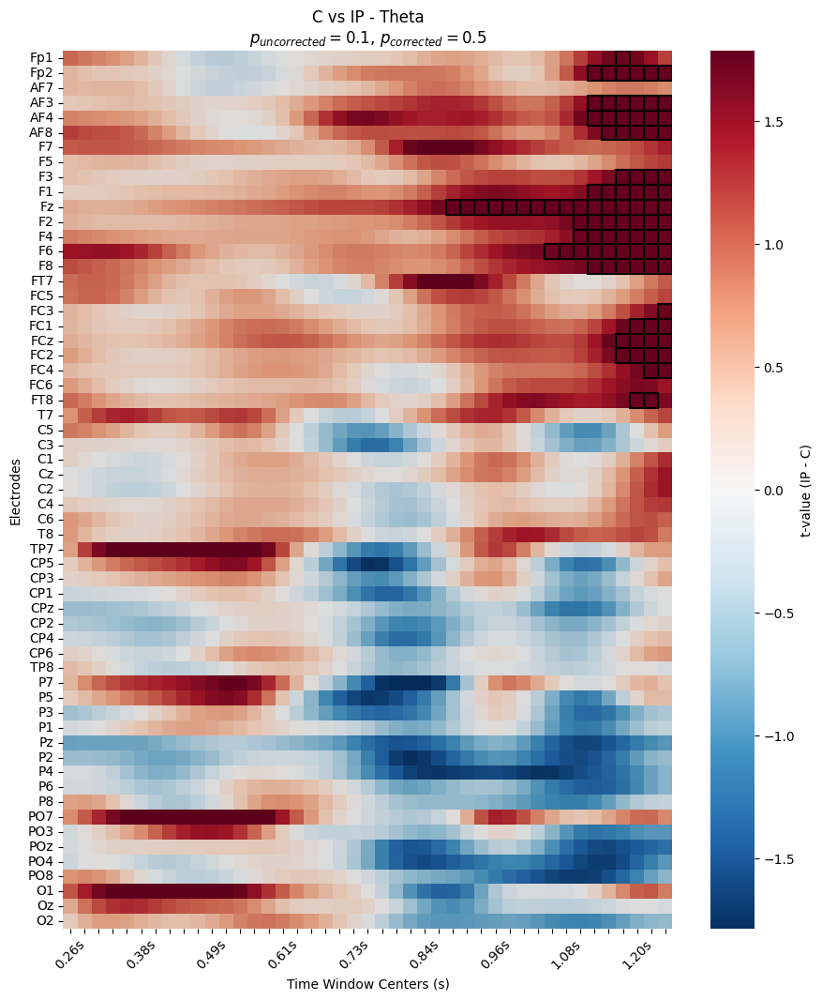

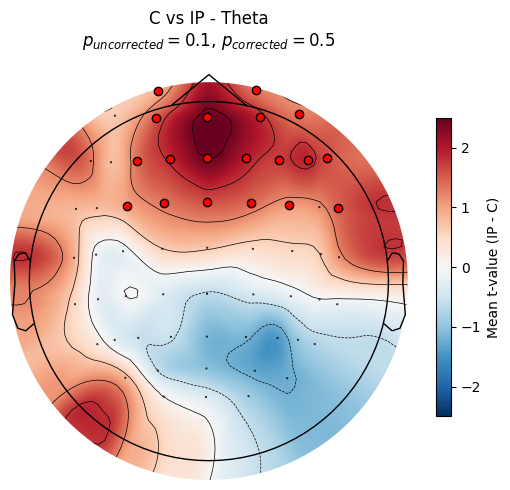


---> Plotting Unique Cluster #2 (ROI: none, p_uncorr=0.05, survived p_corr=0.4)


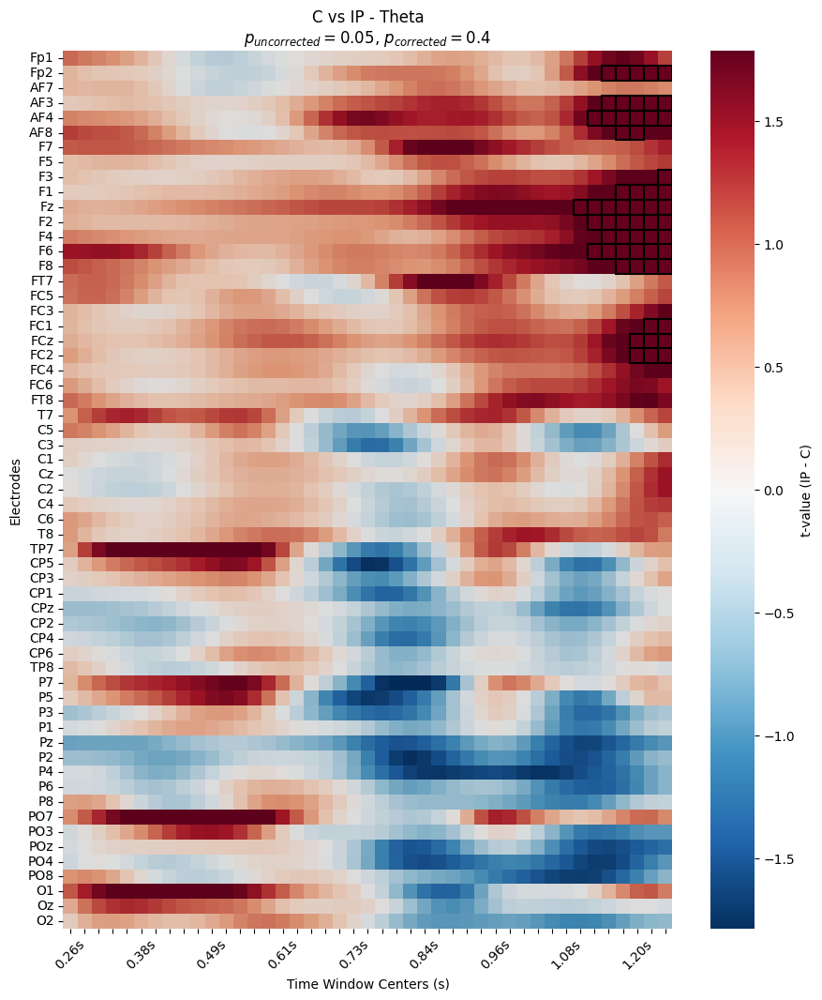

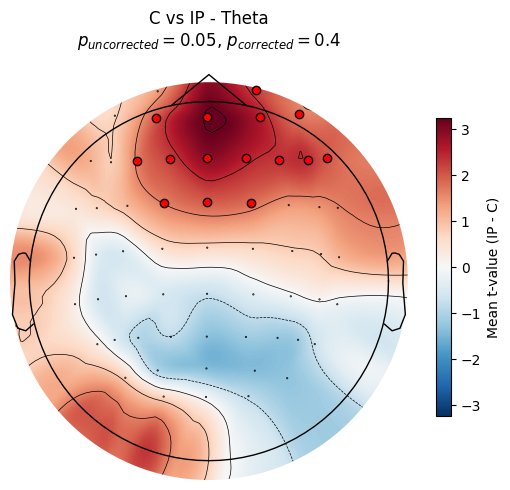


---> Plotting Unique Cluster #3 (ROI: none, p_uncorr=0.01, survived p_corr=0.25)


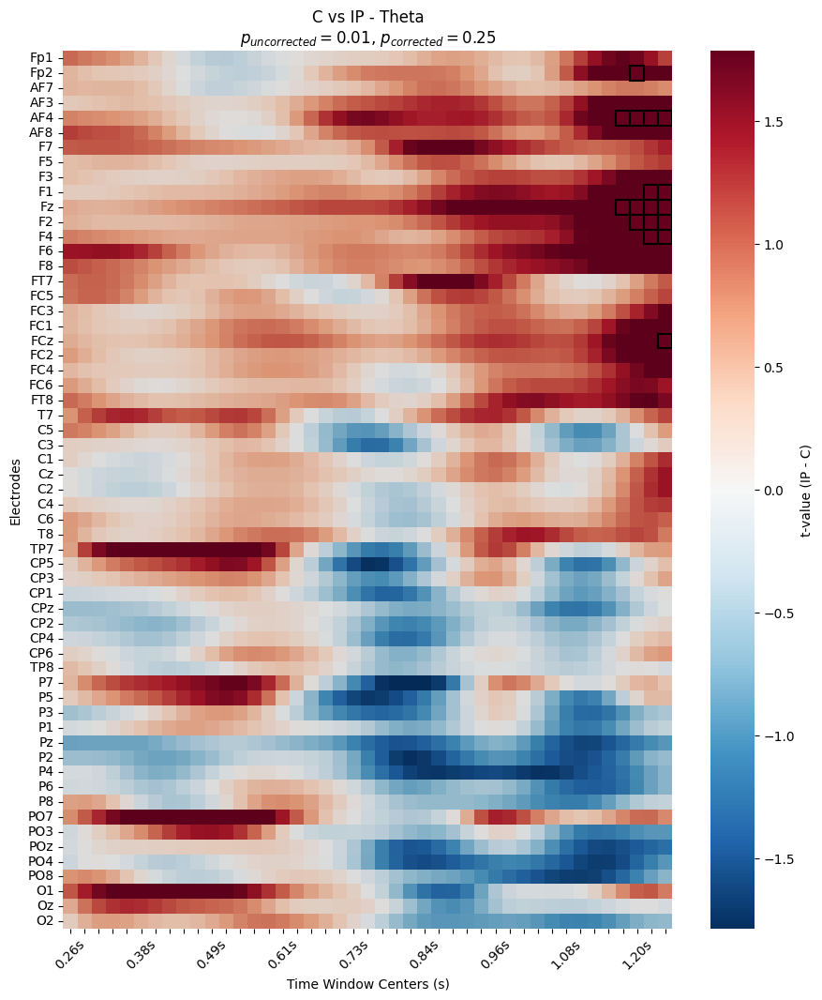

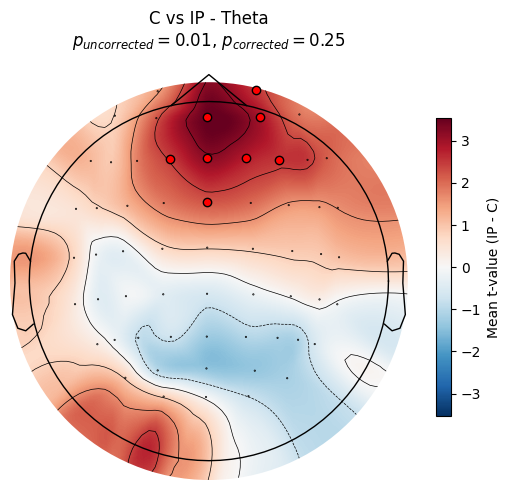


---> Plotting Unique Cluster #4 (ROI: none, p_uncorr=0.005, survived p_corr=0.2)


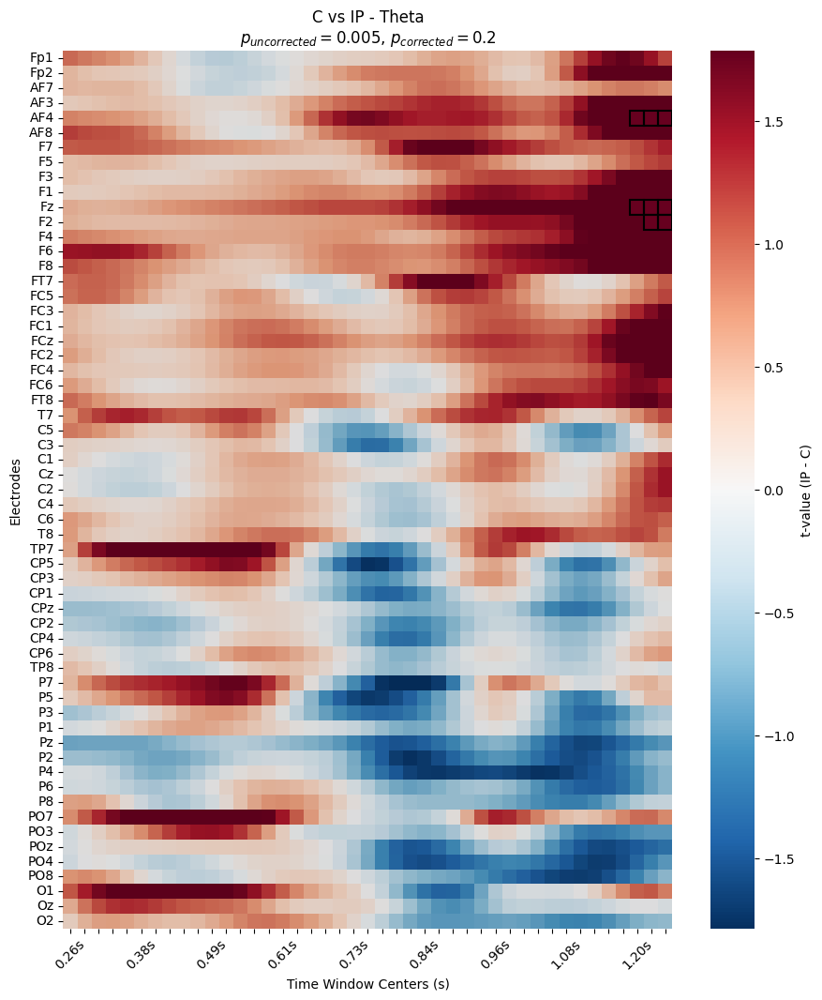

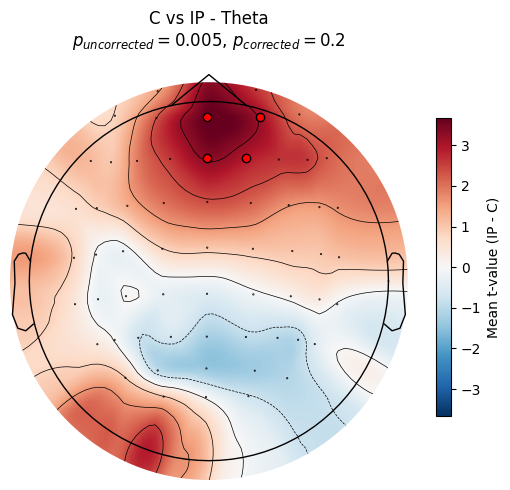


---> Plotting Unique Cluster #5 (ROI: none, p_uncorr=0.001, survived p_corr=0.15)


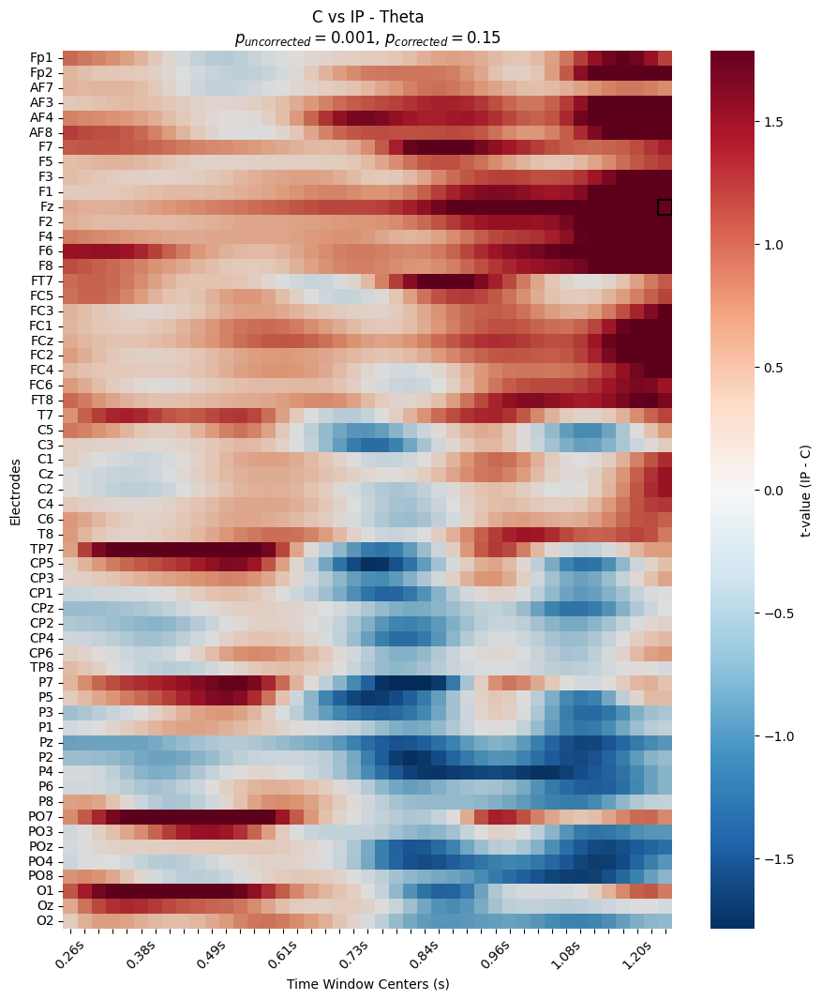

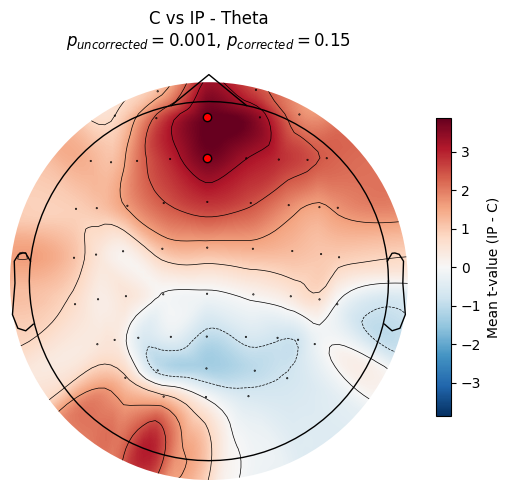


---> Plotting Unique Cluster #6 (ROI: broad, p_uncorr=0.2, survived p_corr=0.4)


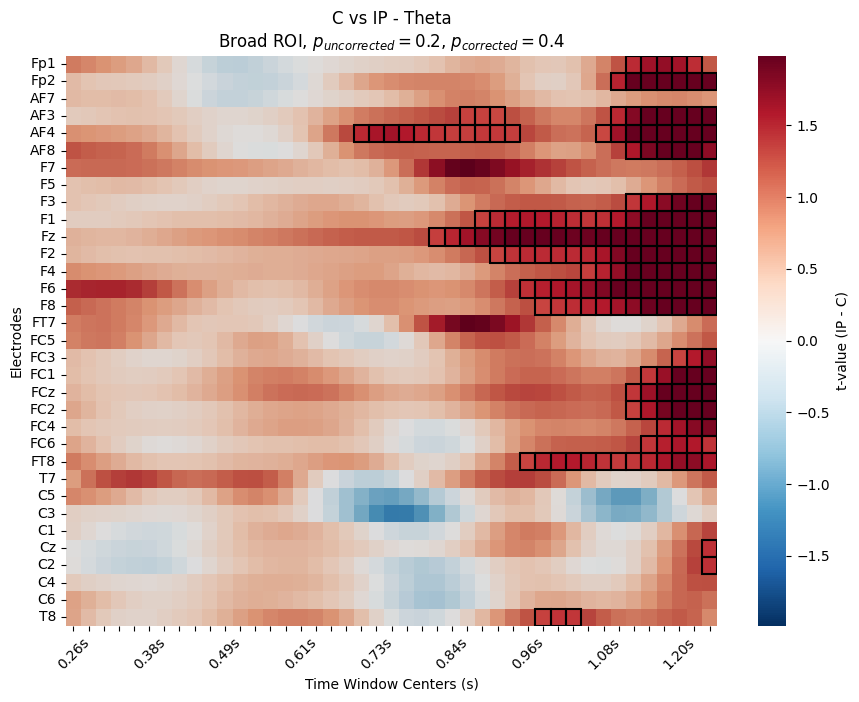

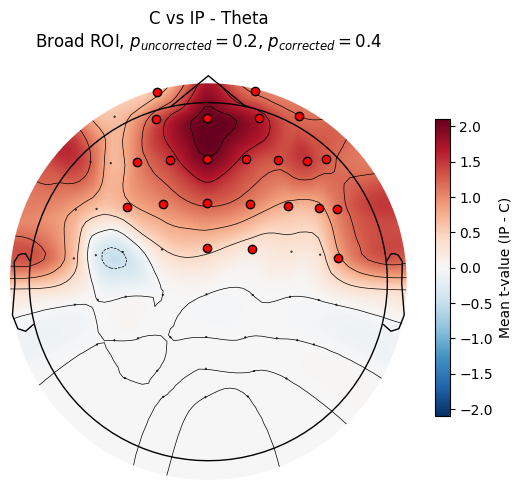


---> Plotting Unique Cluster #7 (ROI: broad, p_uncorr=0.1, survived p_corr=0.35)


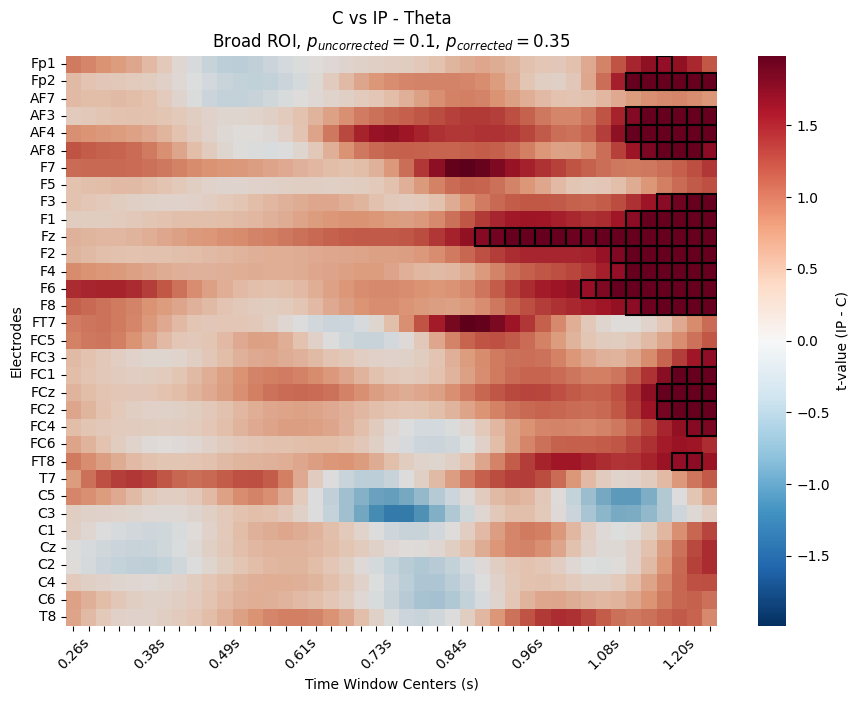

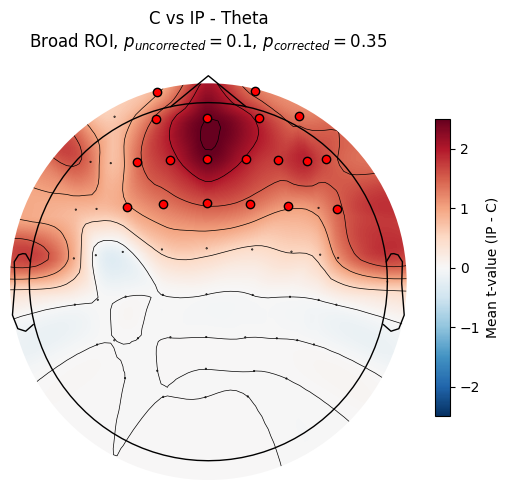


---> Plotting Unique Cluster #8 (ROI: broad, p_uncorr=0.05, survived p_corr=0.25)


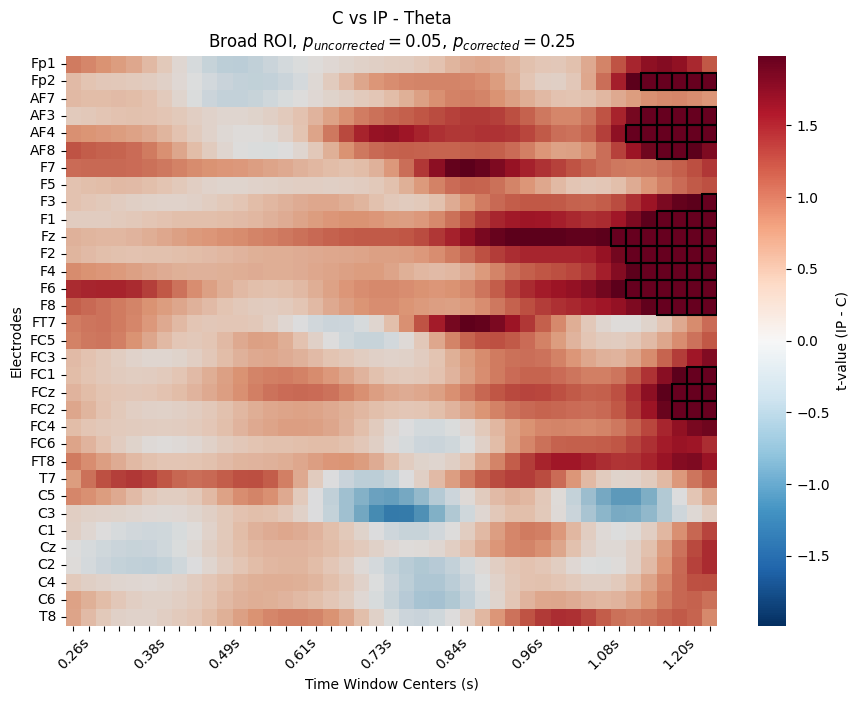

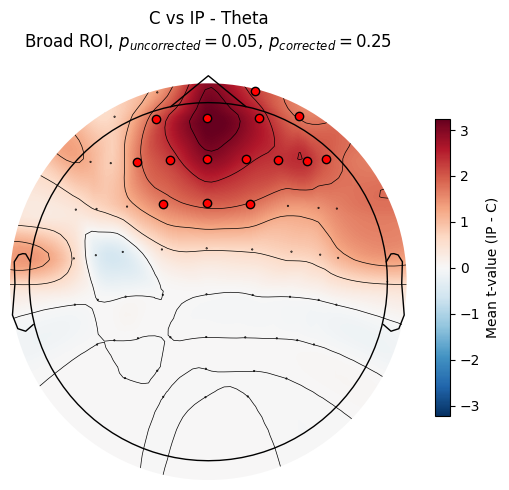


---> Plotting Unique Cluster #9 (ROI: broad, p_uncorr=0.01, survived p_corr=0.15)


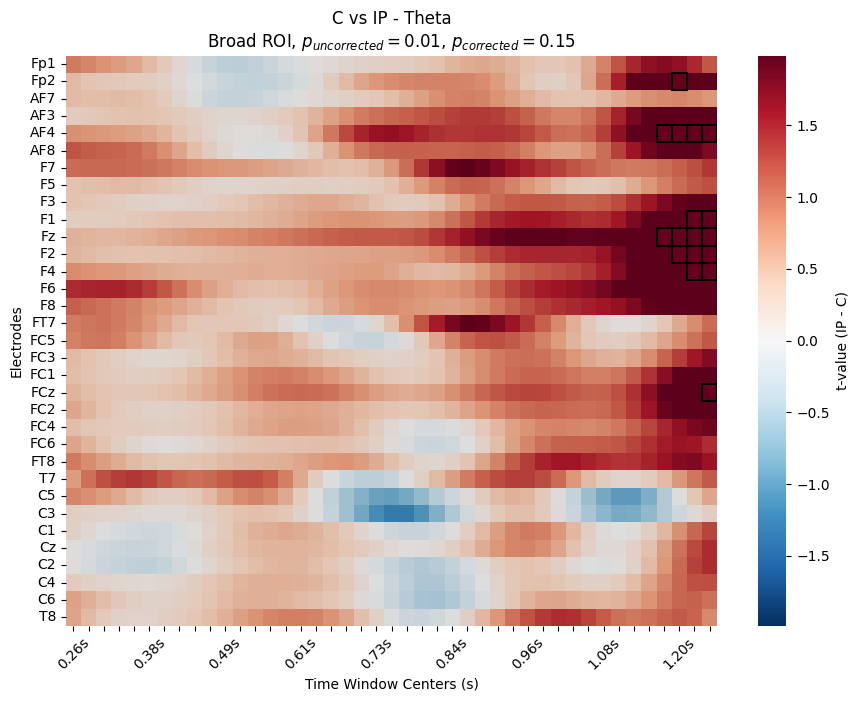

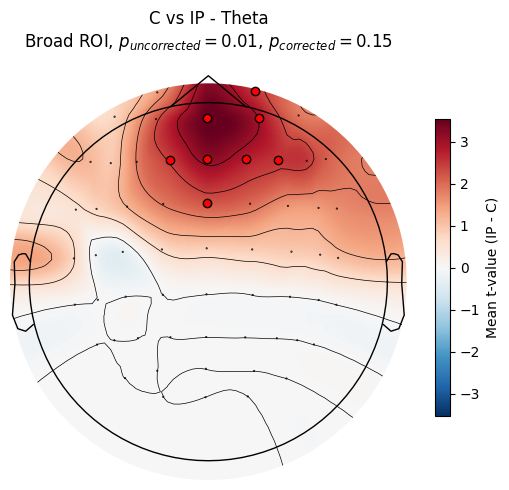


---> Plotting Unique Cluster #10 (ROI: broad, p_uncorr=0.005, survived p_corr=0.15)


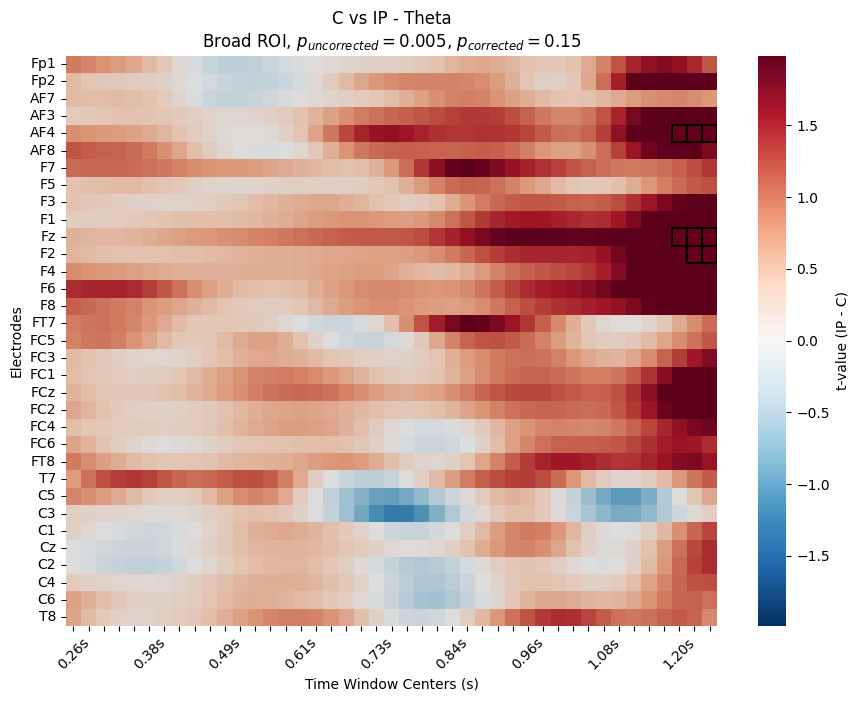

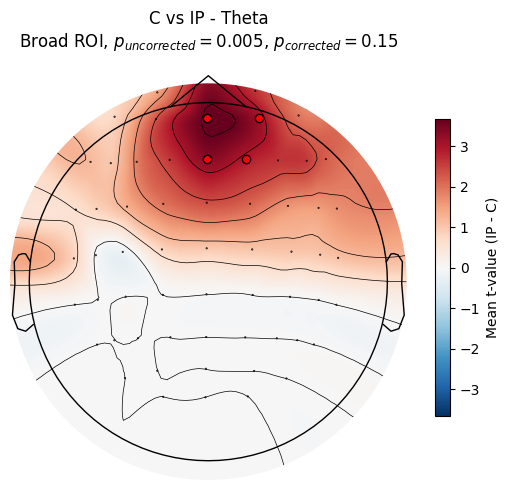


---> Plotting Unique Cluster #11 (ROI: broad, p_uncorr=0.001, survived p_corr=0.1)


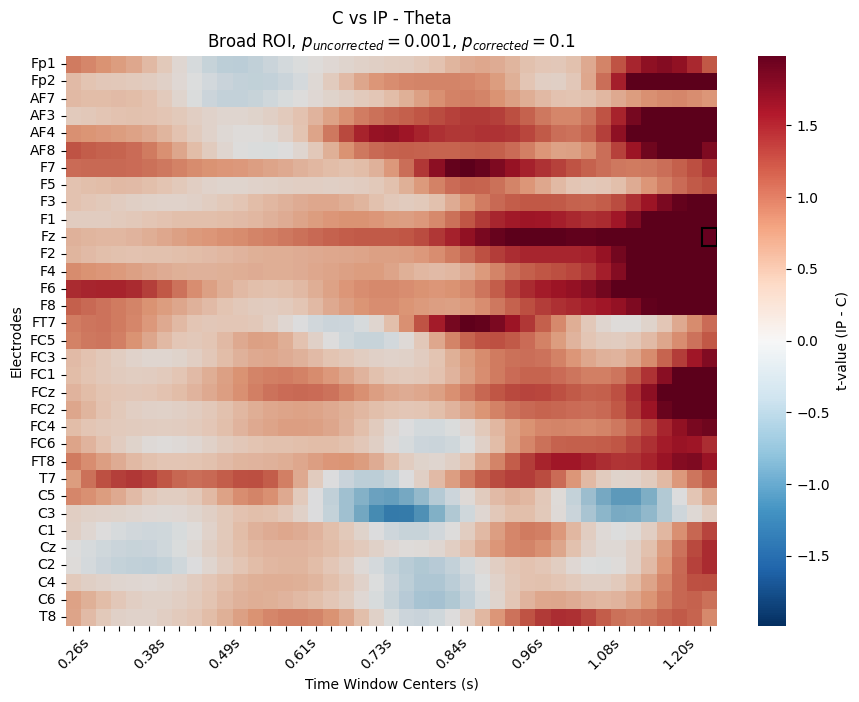

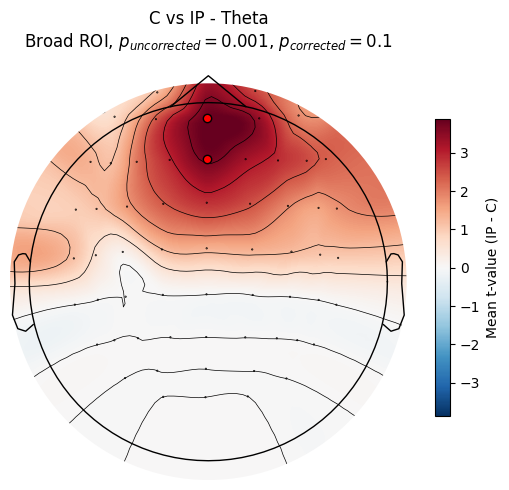


---> Plotting Unique Cluster #12 (ROI: narrow, p_uncorr=0.2, survived p_corr=0.25)


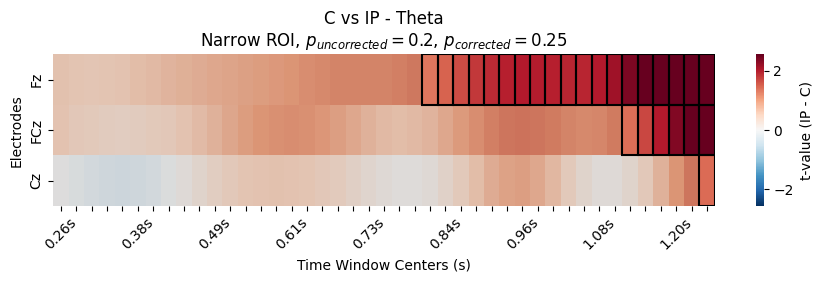

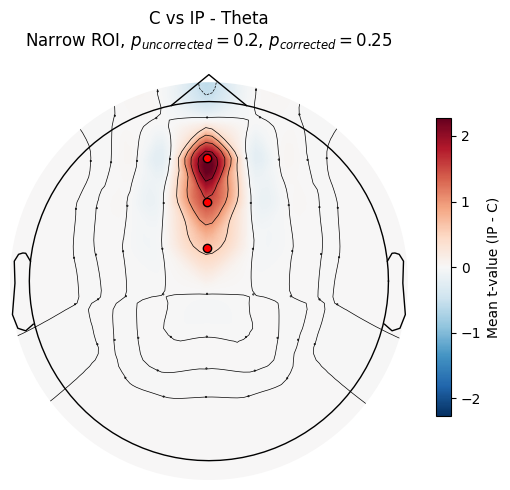


---> Plotting Unique Cluster #13 (ROI: narrow, p_uncorr=0.1, survived p_corr=0.2)


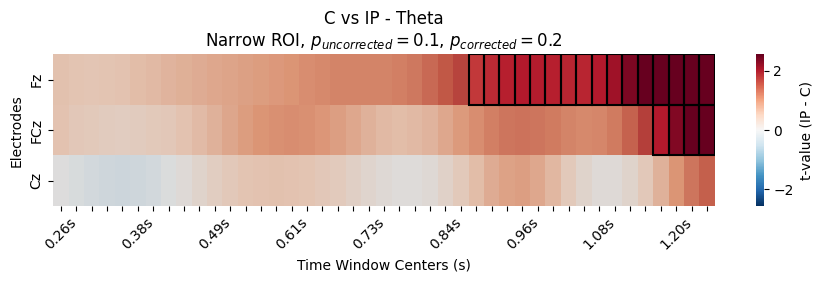

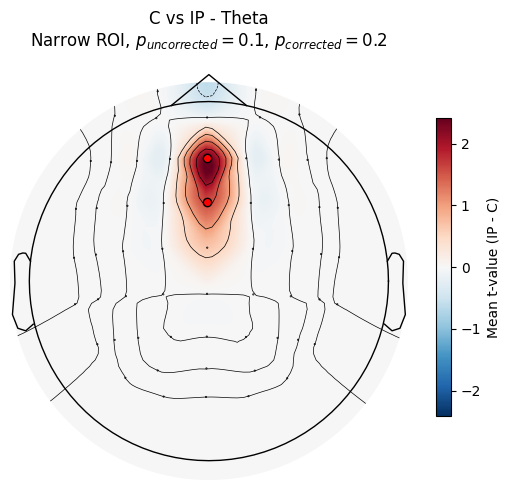


---> Plotting Unique Cluster #14 (ROI: narrow, p_uncorr=0.05, survived p_corr=0.15)


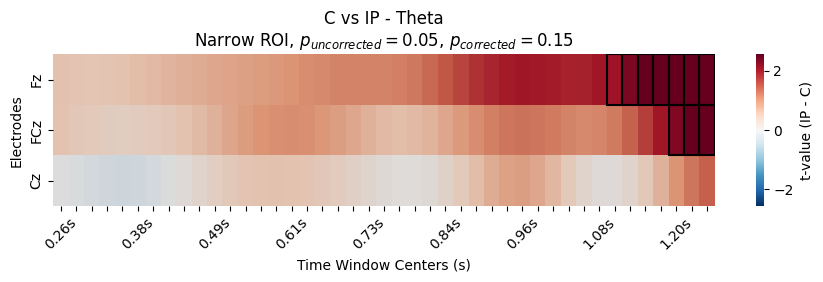

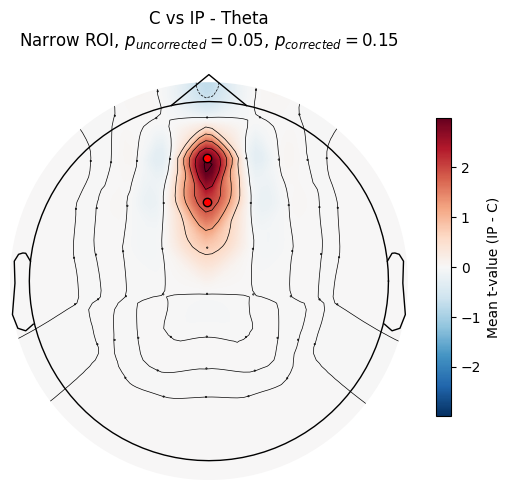


---> Plotting Unique Cluster #15 (ROI: narrow, p_uncorr=0.01, survived p_corr=0.1)


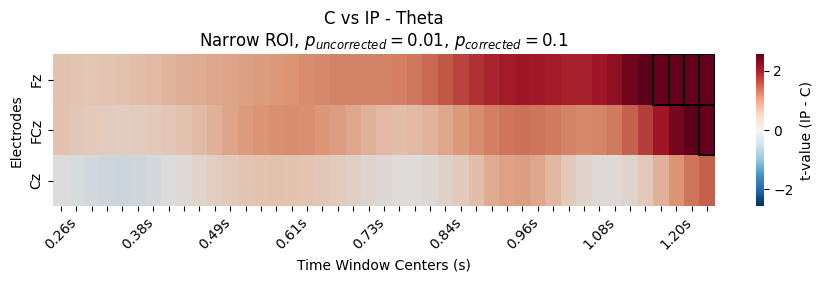

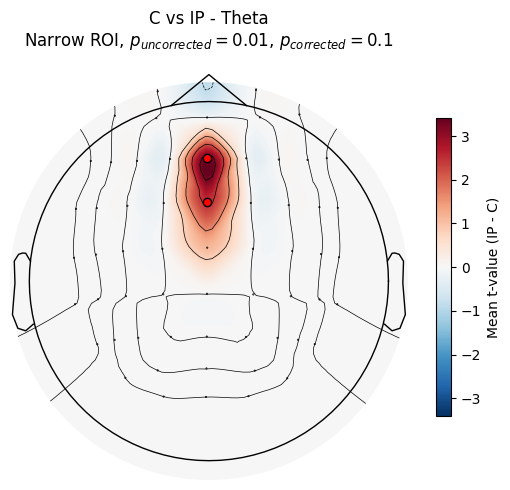


---> Plotting Unique Cluster #16 (ROI: narrow, p_uncorr=0.005, survived p_corr=0.1)


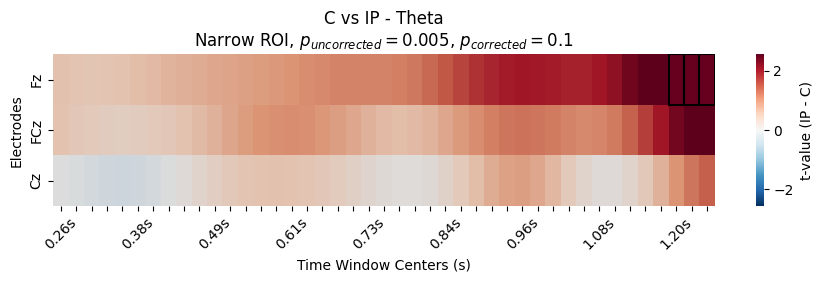

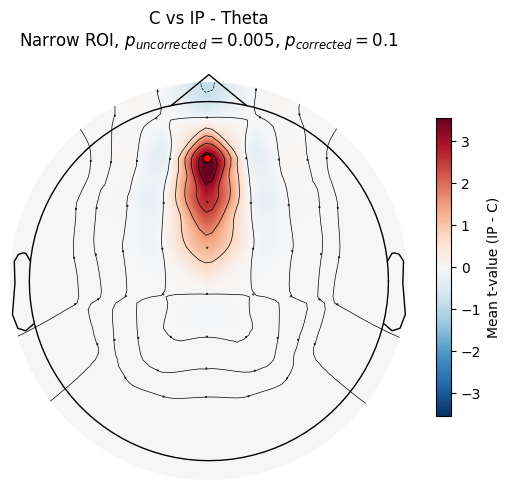


---> Plotting Unique Cluster #17 (ROI: narrow, p_uncorr=0.001, survived p_corr=0.05)


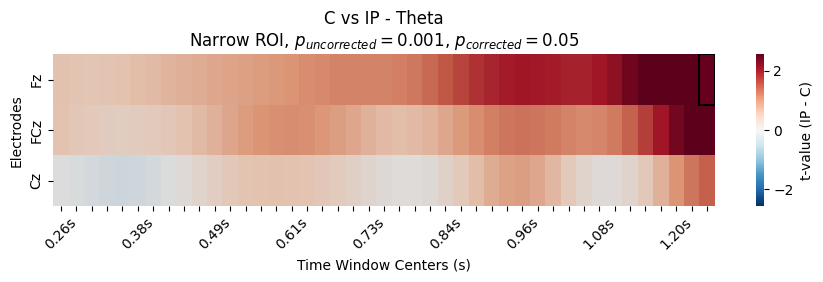

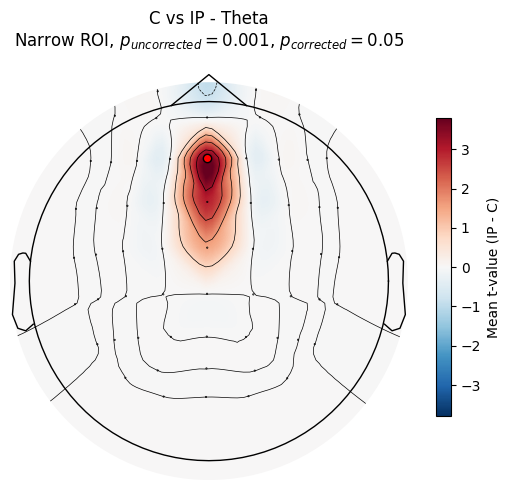


Plotting C vs IP Alpha significant clusters:

---> Plotting Unique Cluster #1 (ROI: none, p_uncorr=0.2, survived p_corr=0.005)


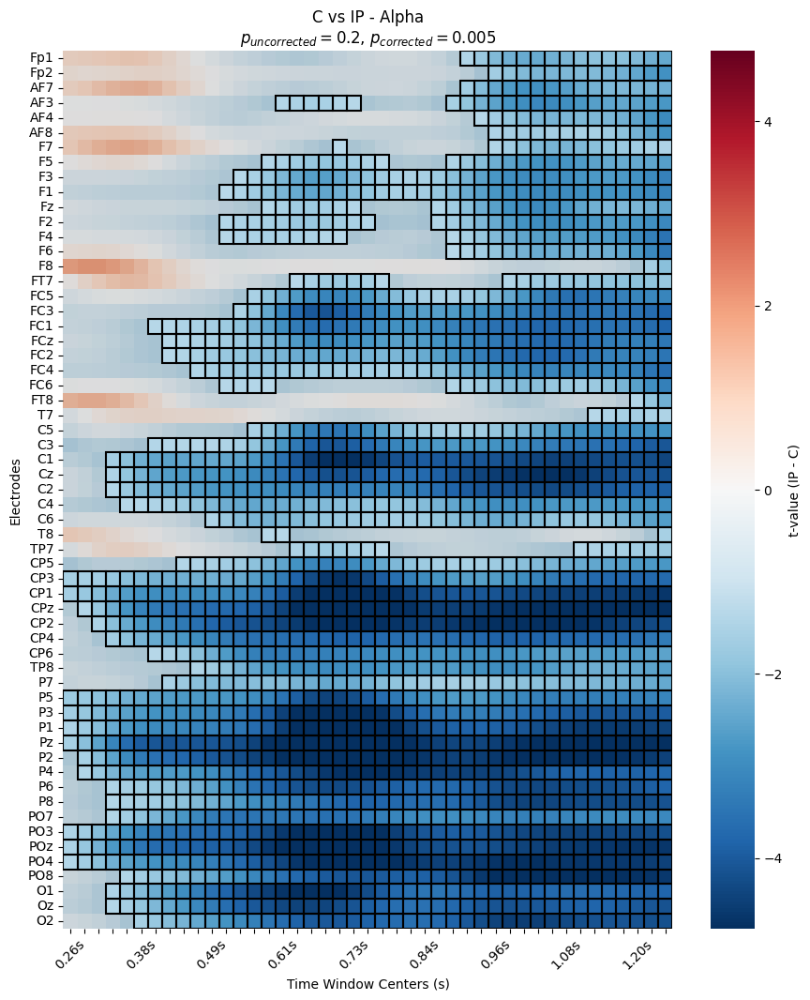

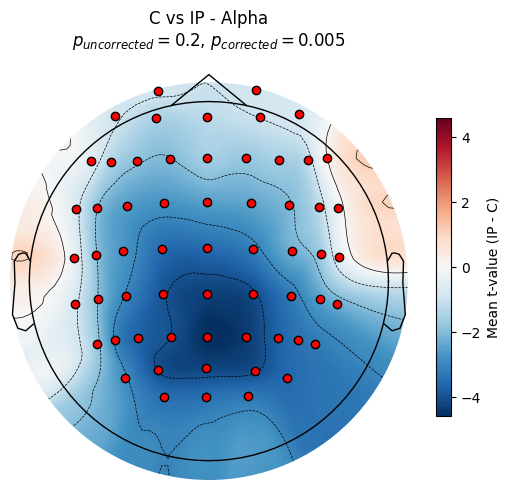


---> Plotting Unique Cluster #2 (ROI: none, p_uncorr=0.1, survived p_corr=0.005)


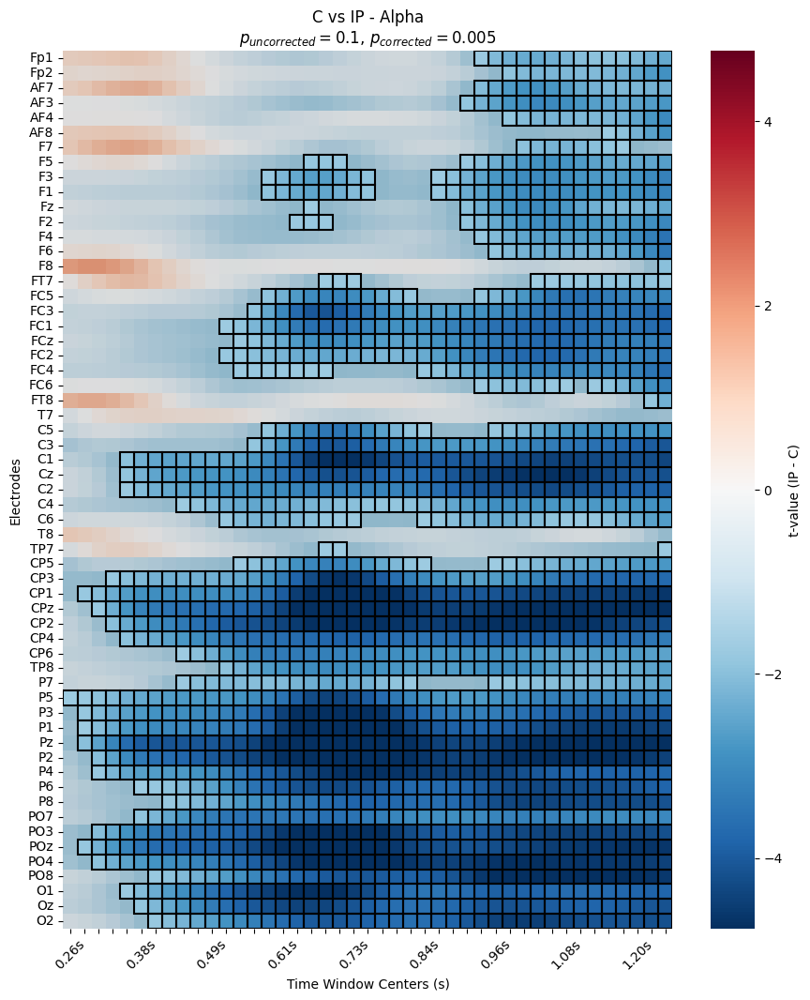

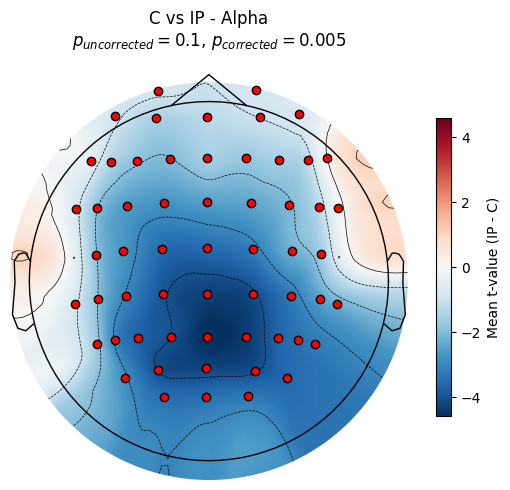


---> Plotting Unique Cluster #3 (ROI: none, p_uncorr=0.05, survived p_corr=0.001)


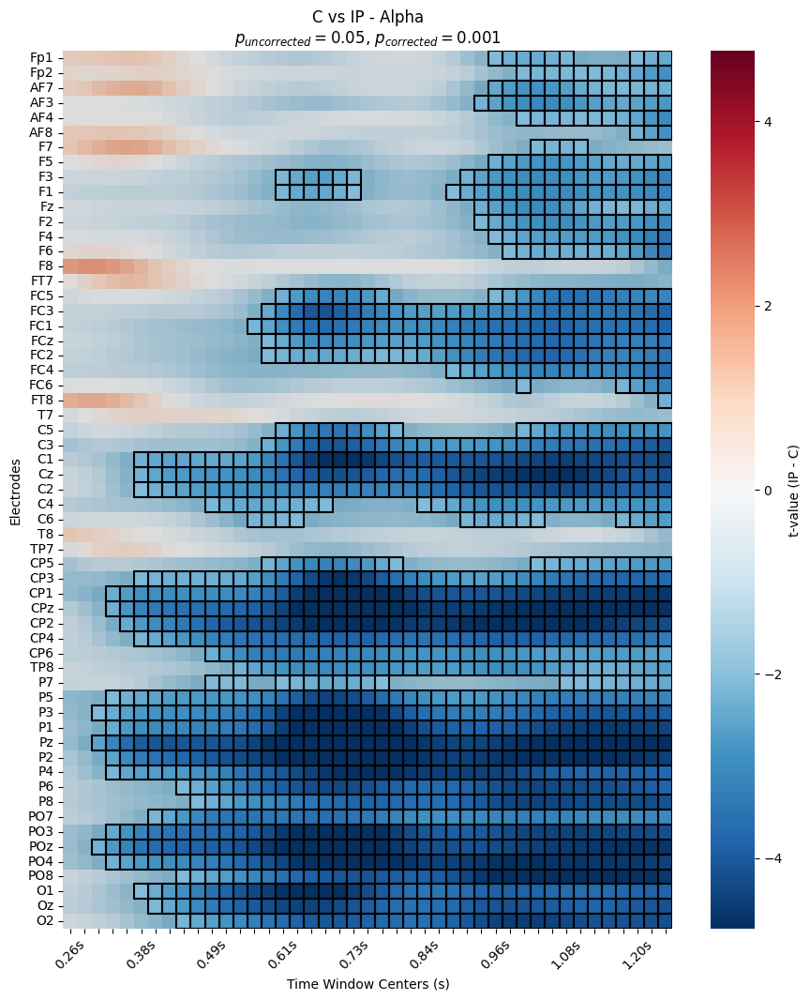

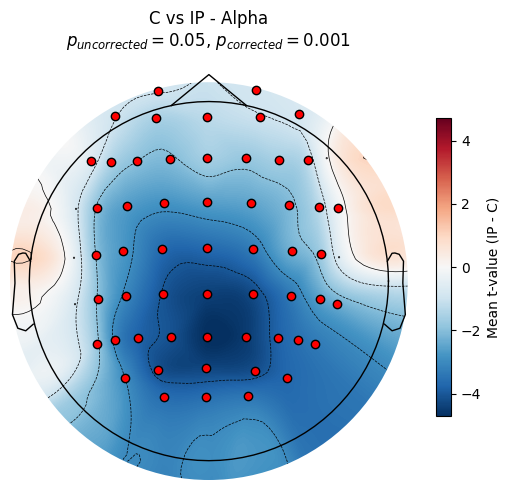


---> Plotting Unique Cluster #4 (ROI: none, p_uncorr=0.01, survived p_corr=0.001)


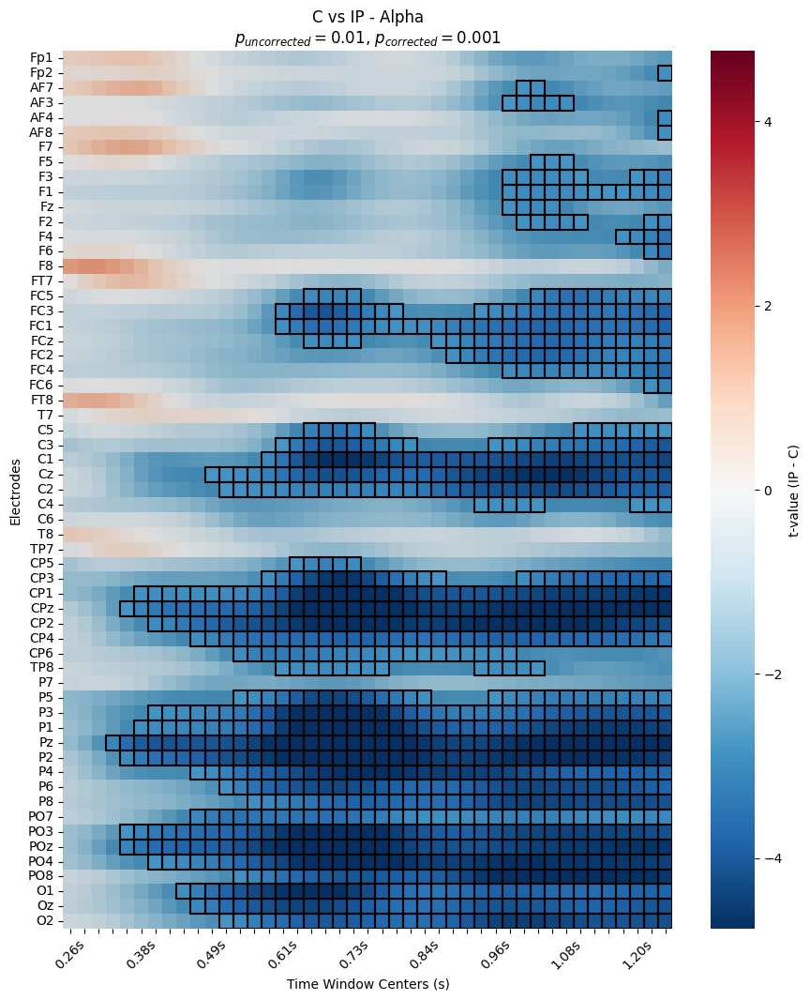

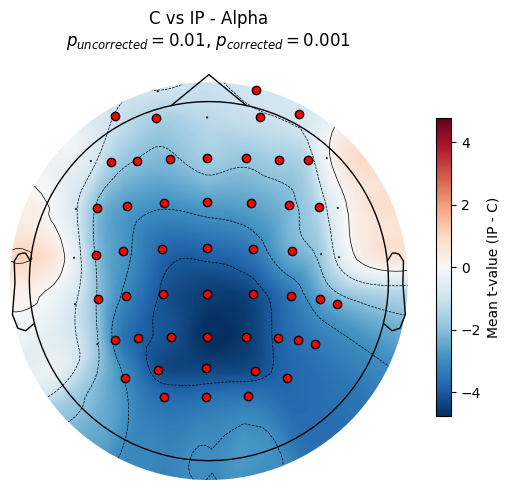


---> Plotting Unique Cluster #5 (ROI: none, p_uncorr=0.005, survived p_corr=0.001)


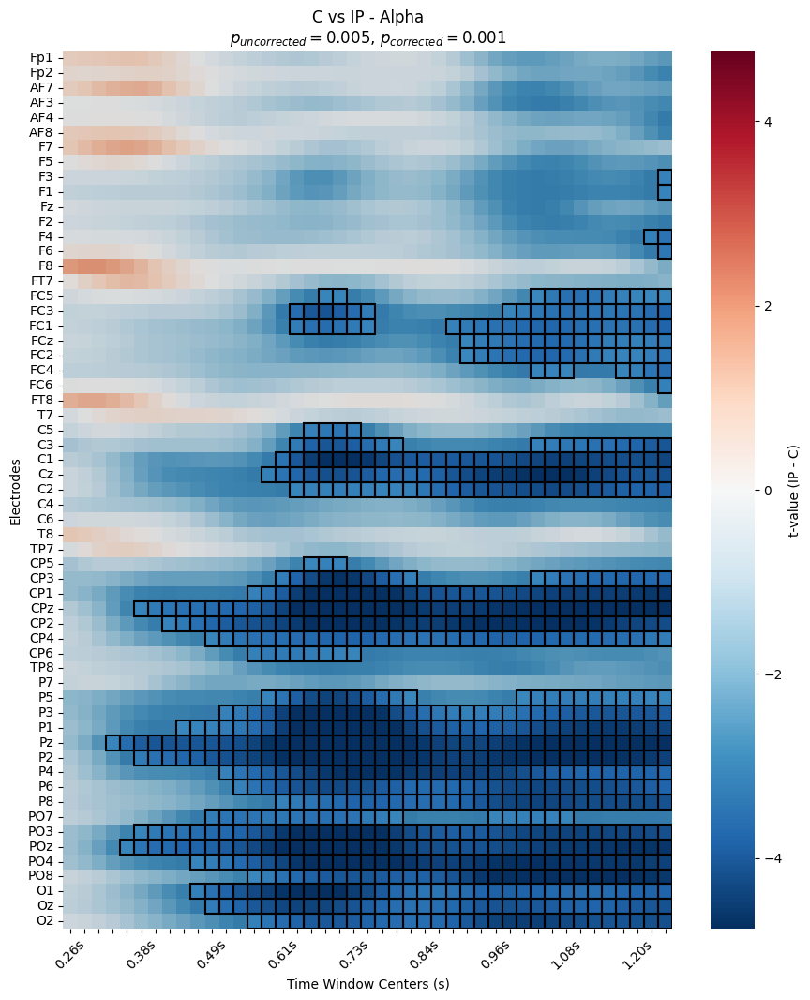

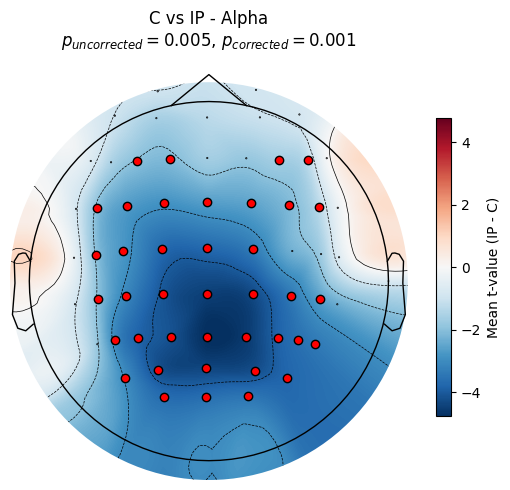


---> Plotting Unique Cluster #6 (ROI: none, p_uncorr=0.001, survived p_corr=0.001)


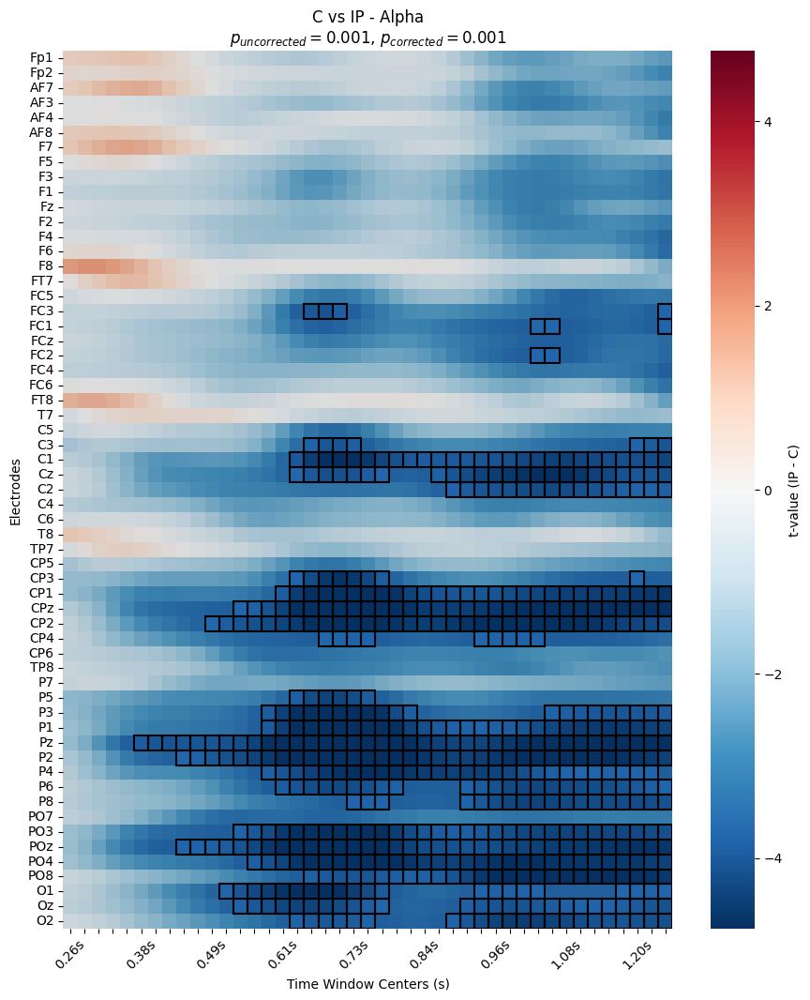

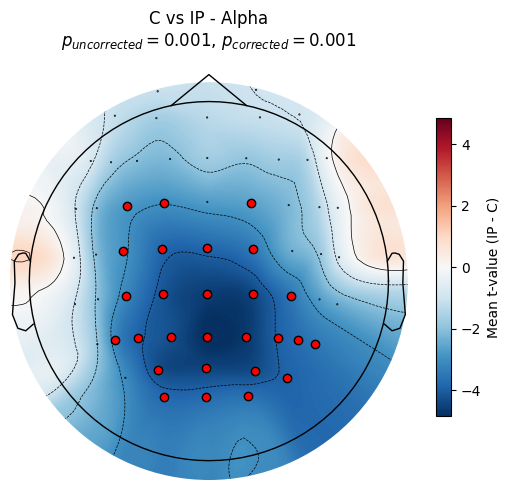


---> Plotting Unique Cluster #7 (ROI: none, p_uncorr=0.0001, survived p_corr=0.001)


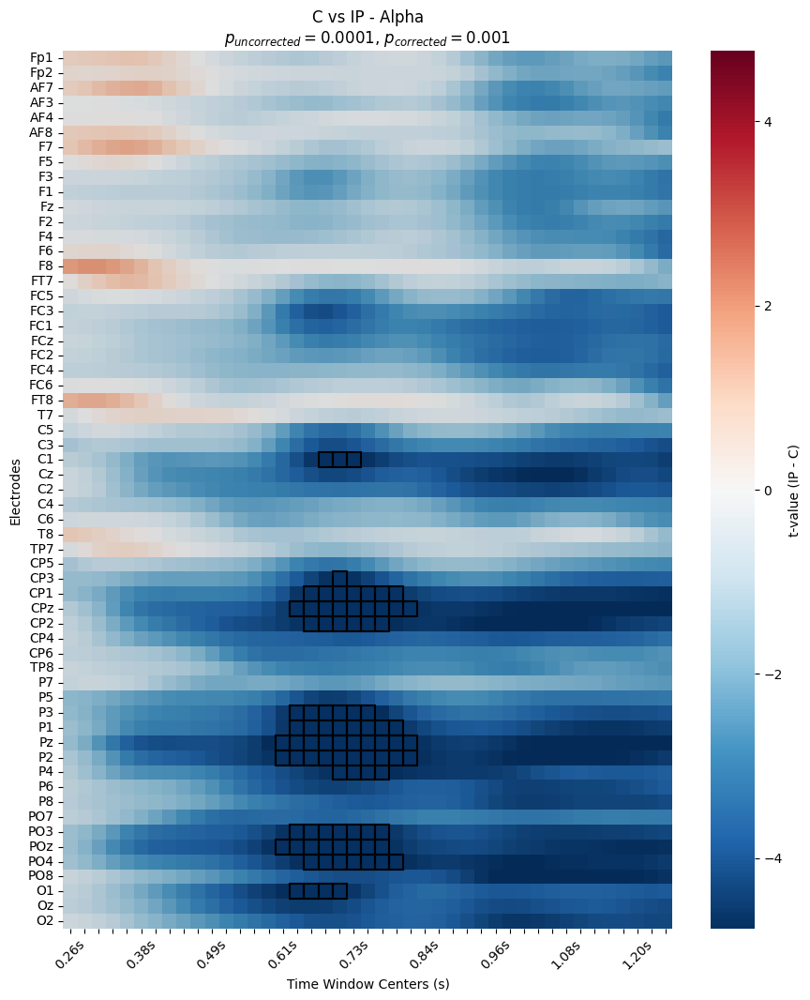

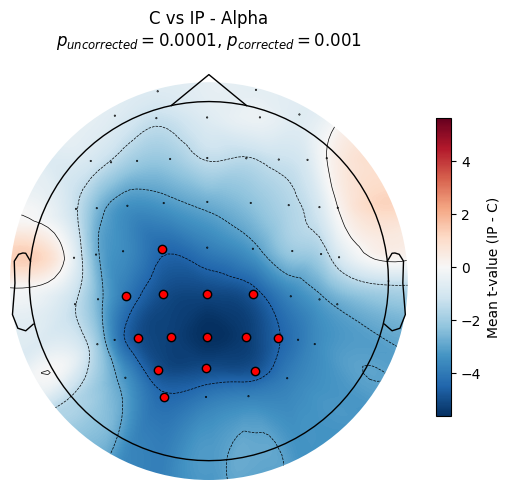


---> Plotting Unique Cluster #8 (ROI: none, p_uncorr=0.0001, survived p_corr=0.001)


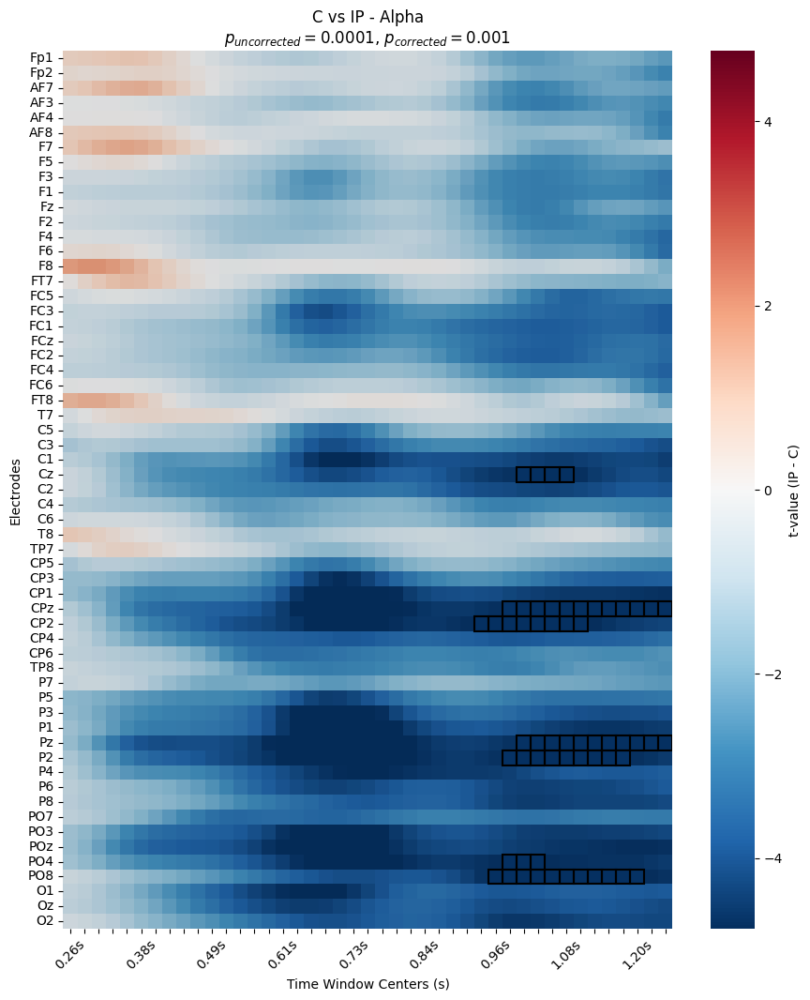

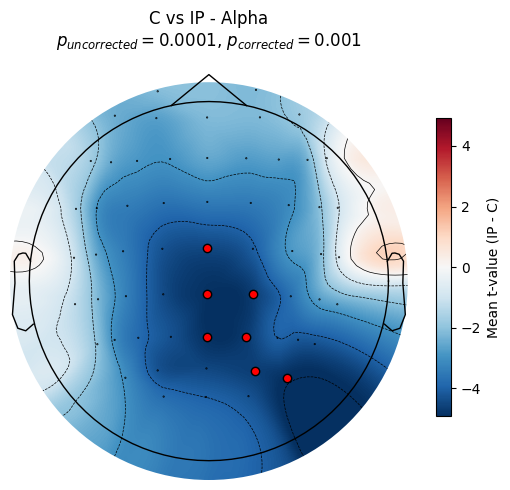

In [17]:
print("\nPlotting C vs IP Theta significant clusters:")
plot_all_significant_unique_clusters(c_theta_res, c_theta_cache, "c_vs_ip", "theta", paths)

print("\nPlotting C vs IP Alpha significant clusters:")
plot_all_significant_unique_clusters(c_alpha_res, c_alpha_cache, "c_vs_ip", "alpha", paths)

## 2. IM vs IP Grid Search & Visualizations (Exploration across Bands & Baselines)

Due to the subtle proactive control nature of IM vs IP, the differences are smaller and often diluted. Here we expand the search to:
- **Bands**: Theta (5-7 Hz) and Alpha (8-12 Hz)
- **Baseline configurations**: Standard dB trial-level baseline vs. No baseline (which highlights sustained block-wide proactive control offsets)
- **ROI Modes**: none, broad, narrow

In [10]:
print("1. Running IM vs IP Theta Grid Search...")
im_theta_res, im_theta_cache = run_grid_search_multi_roi(
    "im_vs_ip",
    "theta",
    (5.0, 7.0),
    paths,
    roi_modes=["none", "broad", "narrow"],
    p_uncorrected=[0.50, 0.25, 0.20, 0.10, 0.05, 0.01, 0.005, 0.001],
    n_permutations=10000,
)

print("2. Running IM vs IP Alpha Grid Search...")
im_alpha_res, im_alpha_cache = run_grid_search_multi_roi(
    "im_vs_ip",
    "alpha",
    (8.0, 12.0),
    paths,
    roi_modes=["none", "broad", "narrow"],
    p_uncorrected=[0.50, 0.25, 0.20, 0.10, 0.05, 0.01, 0.005, 0.001],
    n_permutations=10000,
)

1. Running IM vs IP Theta Grid Search...
[IM_VS_IP] Loading cached dataset from H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\cache\raw_epochs_dataset_im_vs_ip_sfreq128.joblib...

GRID SEARCH FOR: IM_VS_IP - THETA (NONE ROI, dB baseline)

Running permutation test for p_uncorrected = 0.500 (t_crit = 0.683)...
  -> p_corrected = 0.000: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.001: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.005: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.010: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.050: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.100: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.150: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.200: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.25


Plotting IM vs IP Theta significant clusters:

---> Plotting Unique Cluster #1 (ROI: none, p_uncorr=0.1, survived p_corr=0.4)


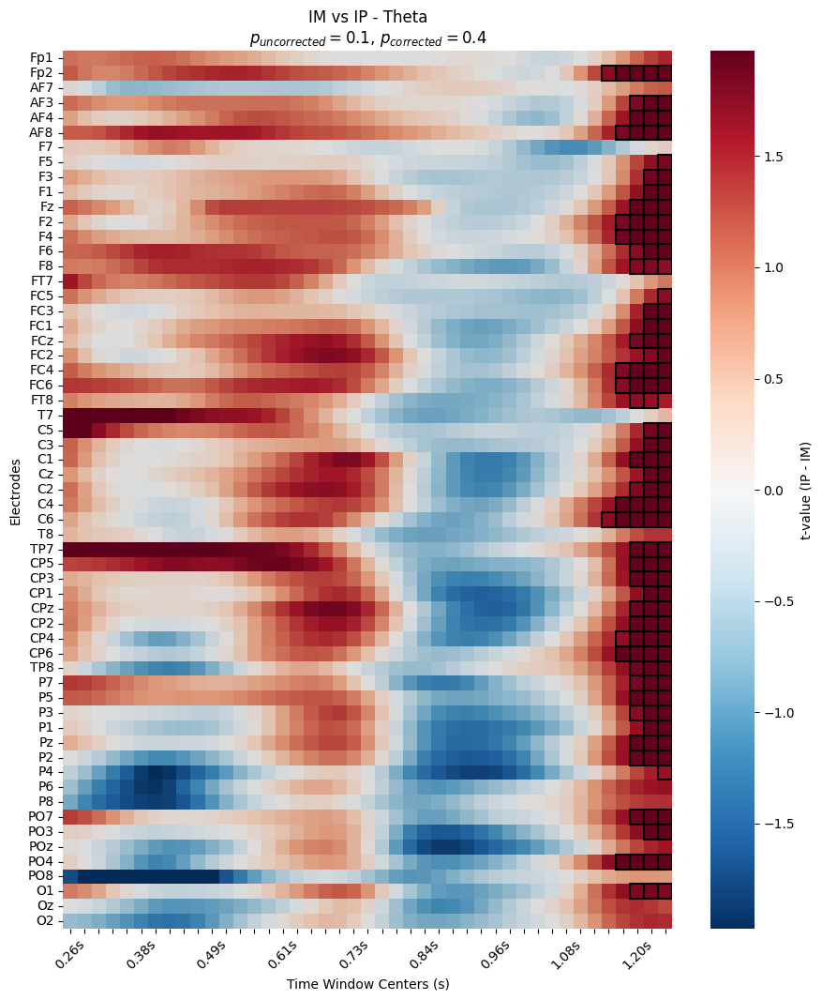

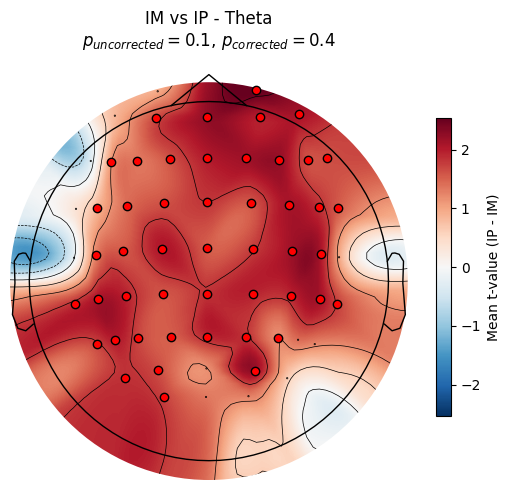


---> Plotting Unique Cluster #2 (ROI: none, p_uncorr=0.05, survived p_corr=0.35)


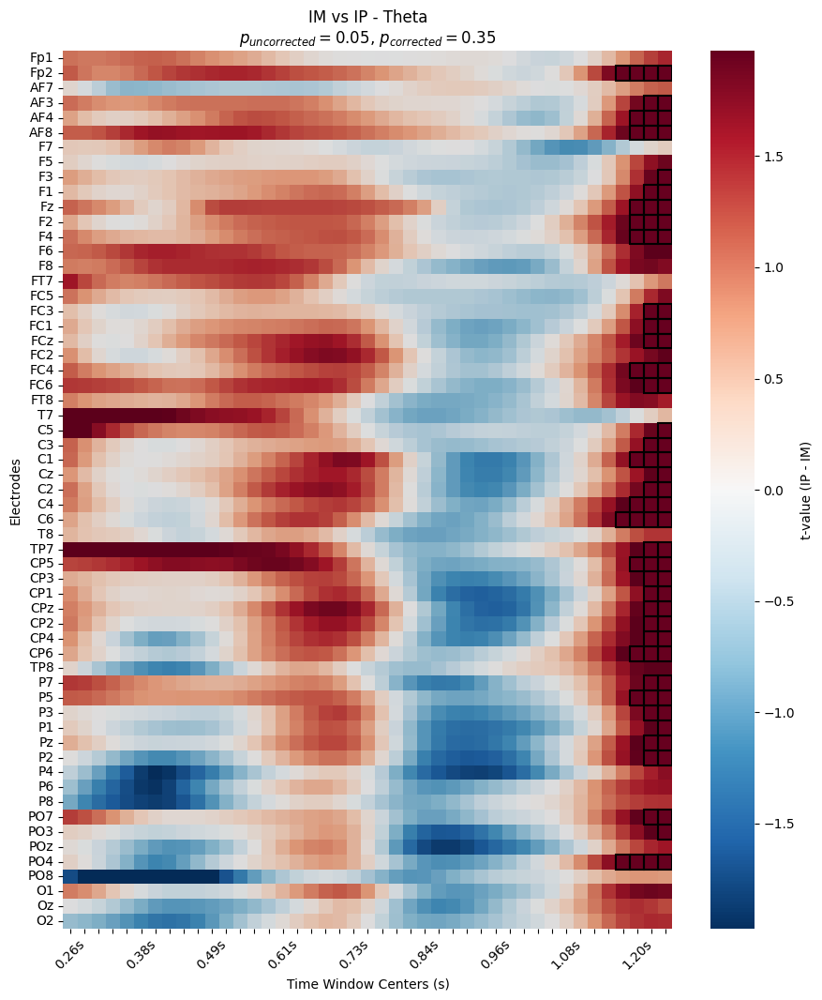

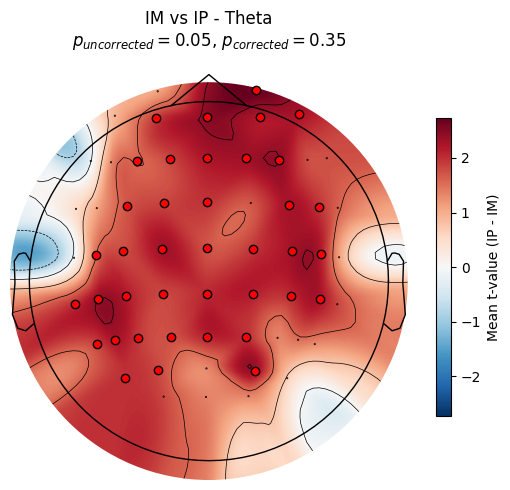


---> Plotting Unique Cluster #3 (ROI: none, p_uncorr=0.01, survived p_corr=0.5)


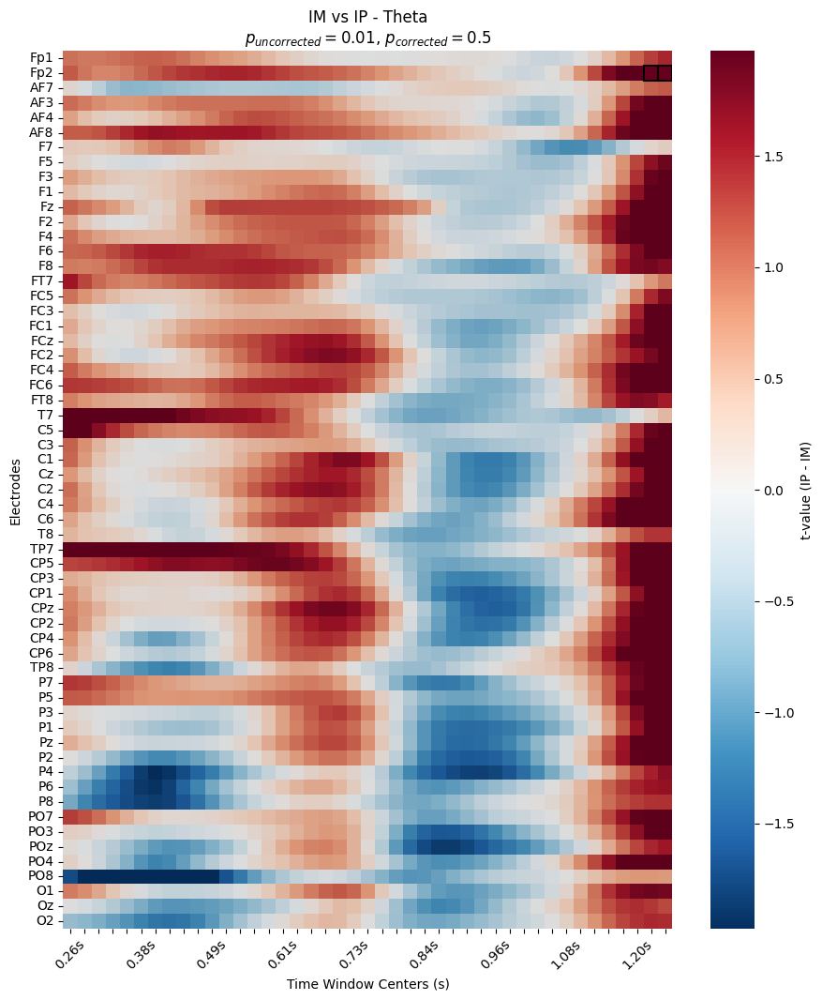

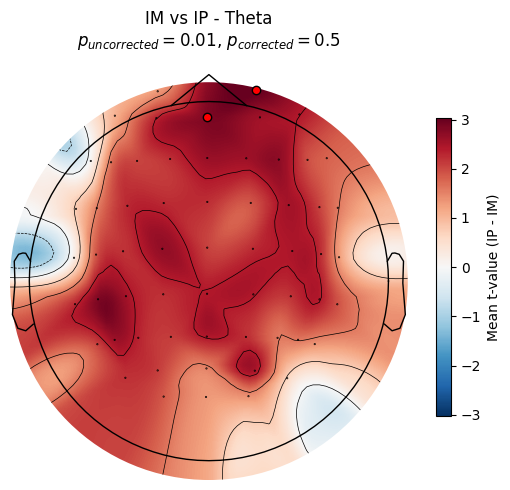


---> Plotting Unique Cluster #4 (ROI: none, p_uncorr=0.005, survived p_corr=0.5)


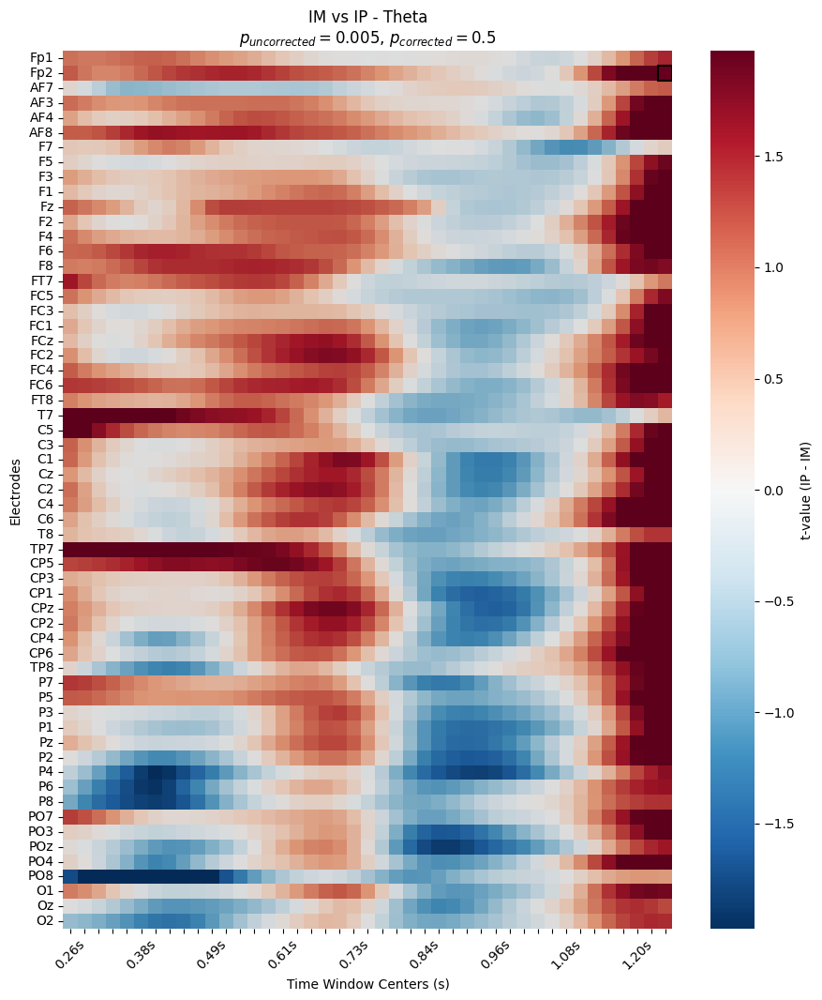

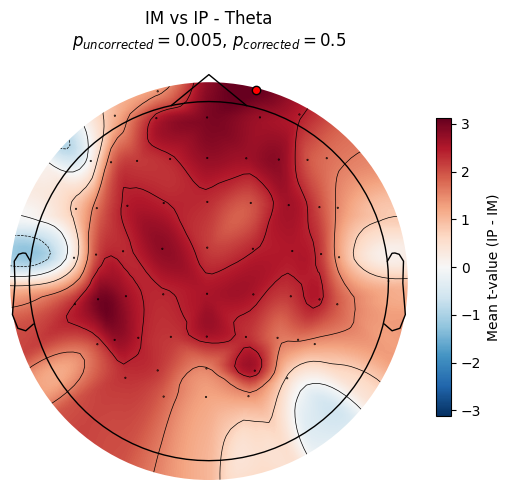


---> Plotting Unique Cluster #5 (ROI: broad, p_uncorr=0.1, survived p_corr=0.4)


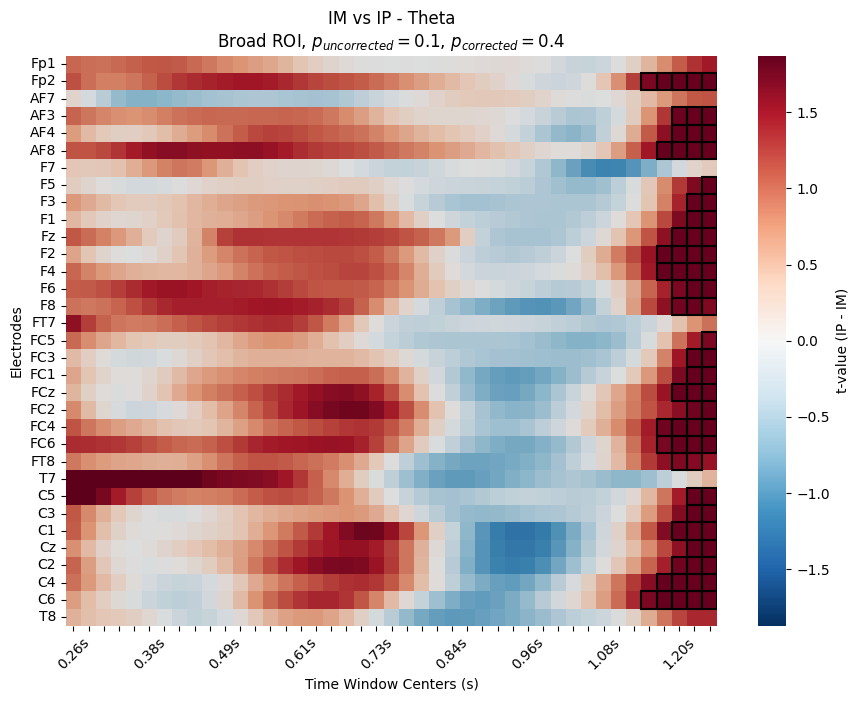

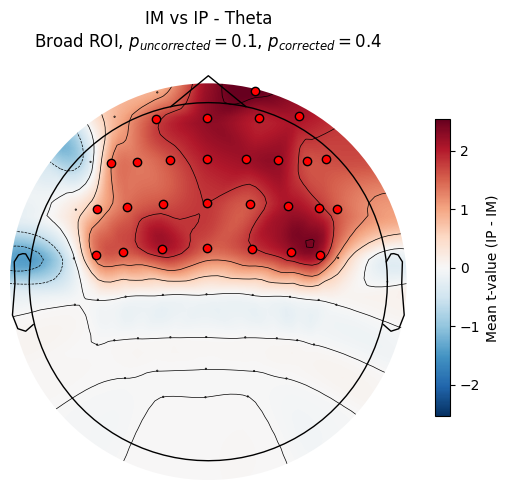


---> Plotting Unique Cluster #6 (ROI: broad, p_uncorr=0.05, survived p_corr=0.3)


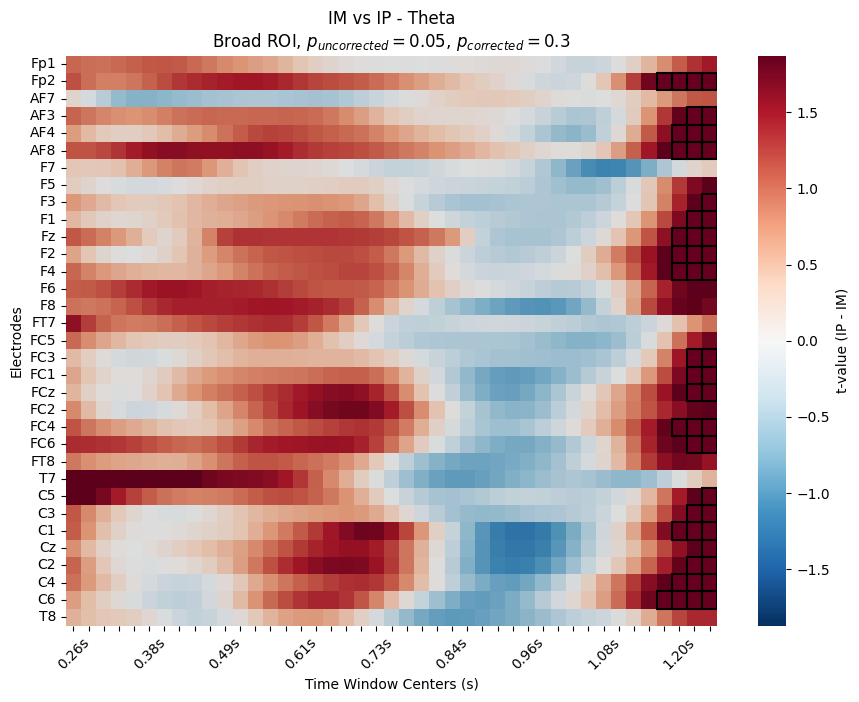

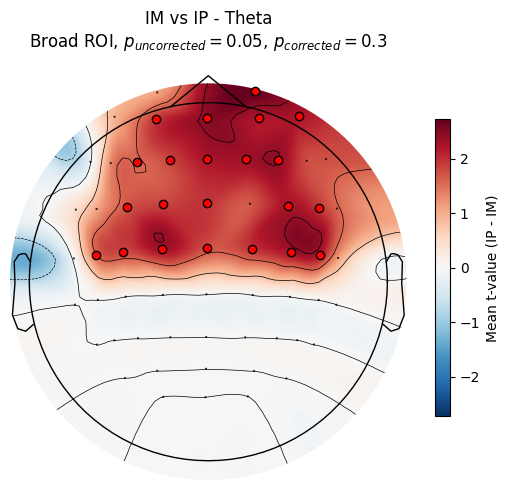


---> Plotting Unique Cluster #7 (ROI: broad, p_uncorr=0.01, survived p_corr=0.4)


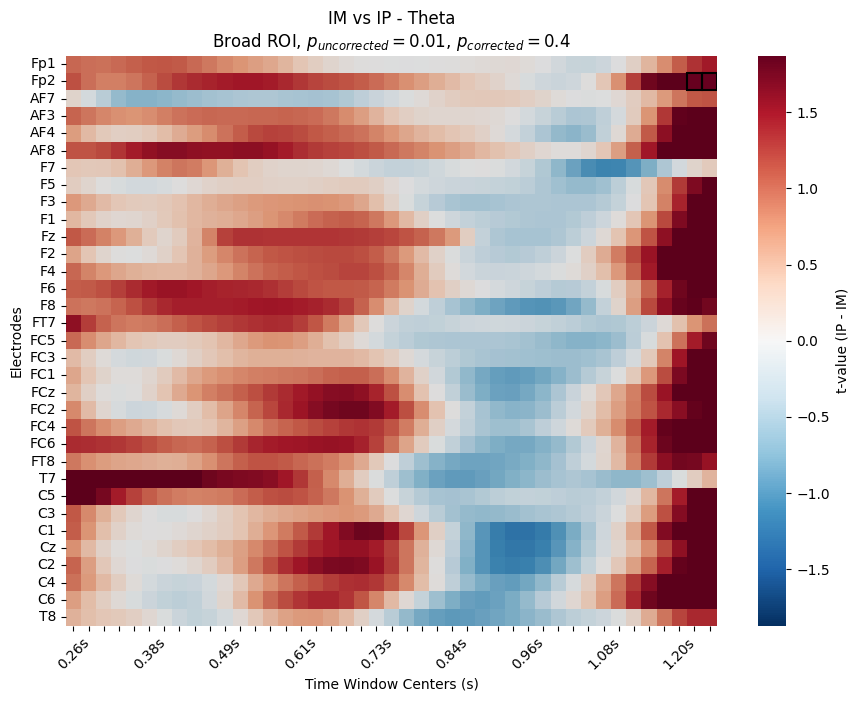

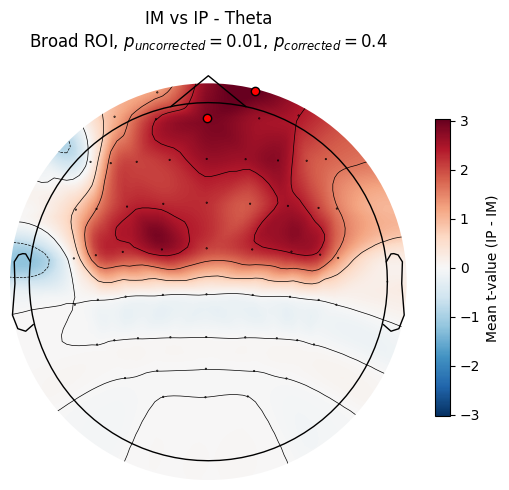


---> Plotting Unique Cluster #8 (ROI: broad, p_uncorr=0.01, survived p_corr=0.5)


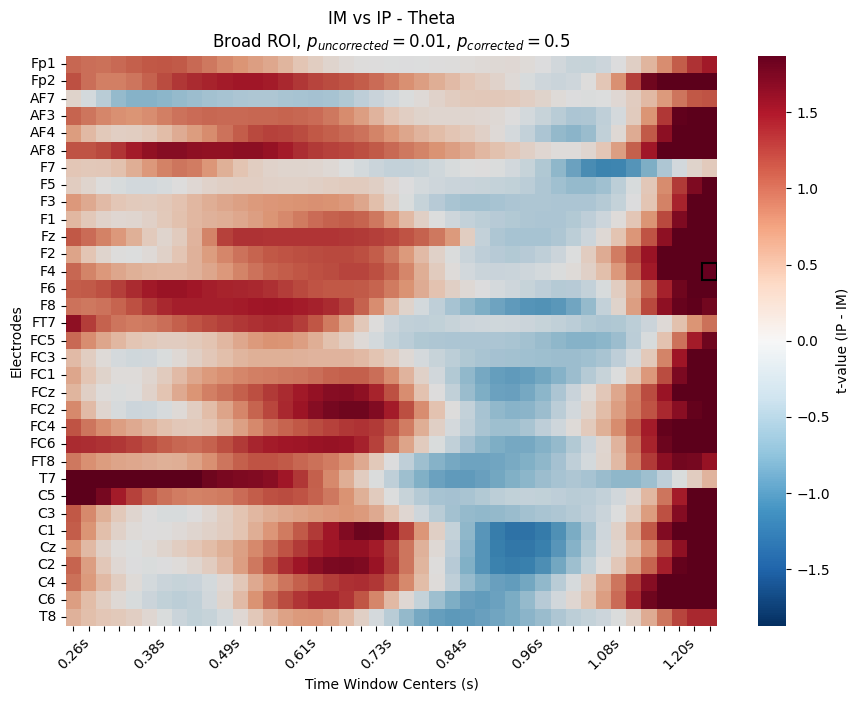

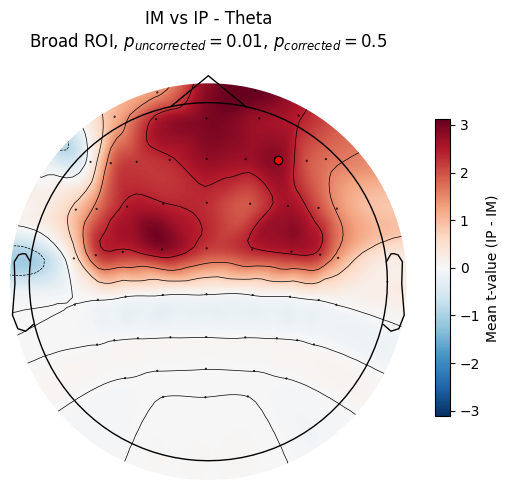


---> Plotting Unique Cluster #9 (ROI: broad, p_uncorr=0.01, survived p_corr=0.5)


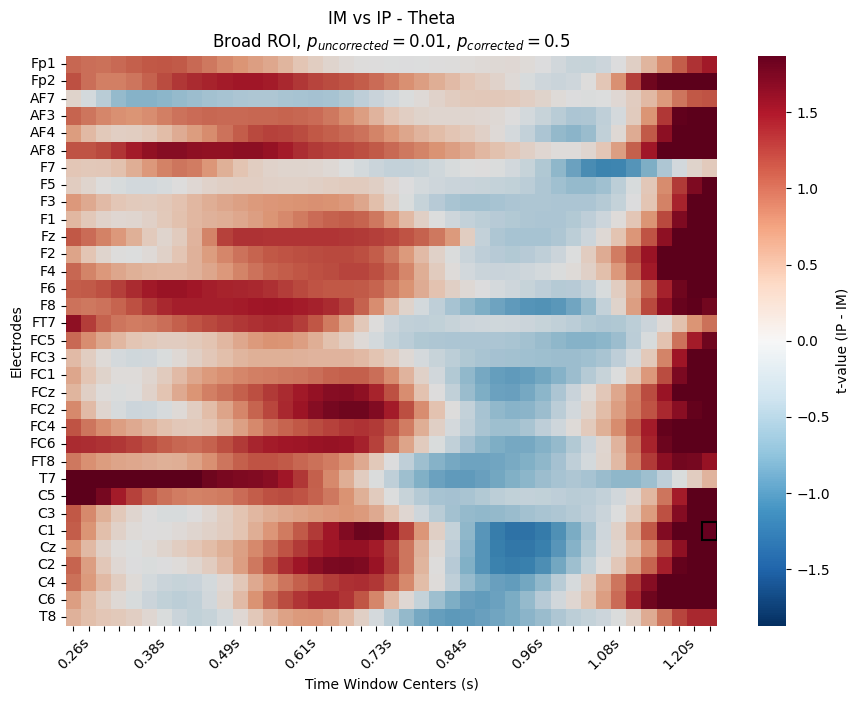

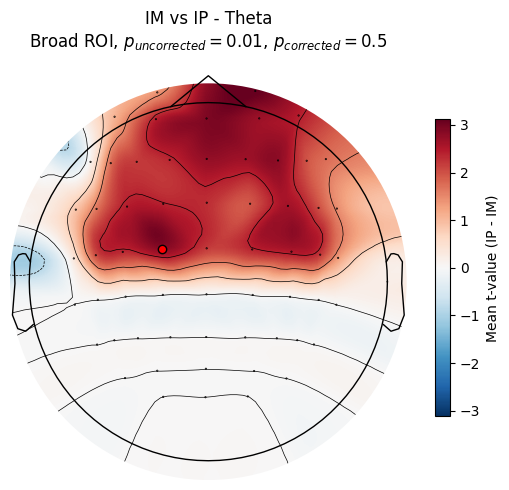


---> Plotting Unique Cluster #10 (ROI: broad, p_uncorr=0.005, survived p_corr=0.35)


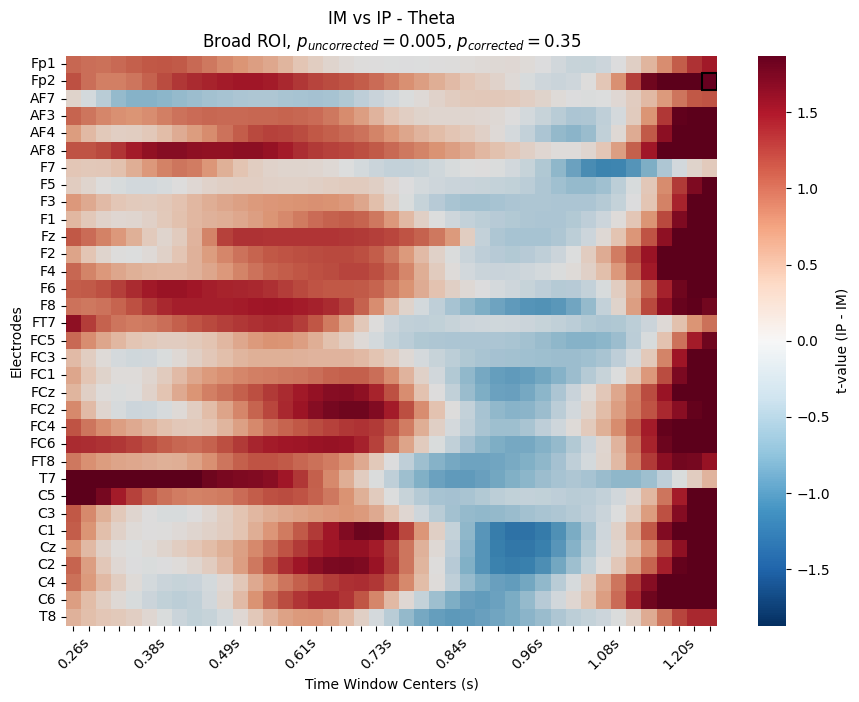

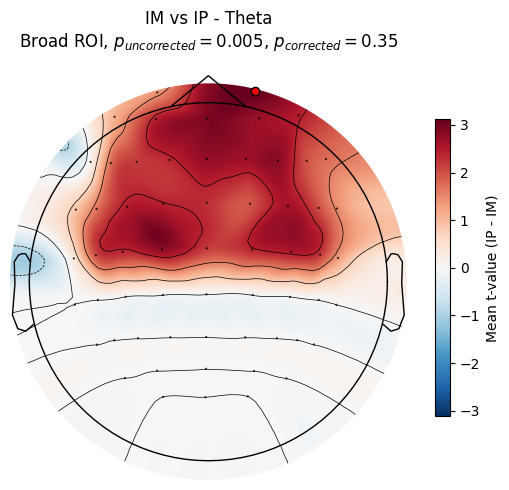


---> Plotting Unique Cluster #11 (ROI: narrow, p_uncorr=0.5, survived p_corr=0.5)


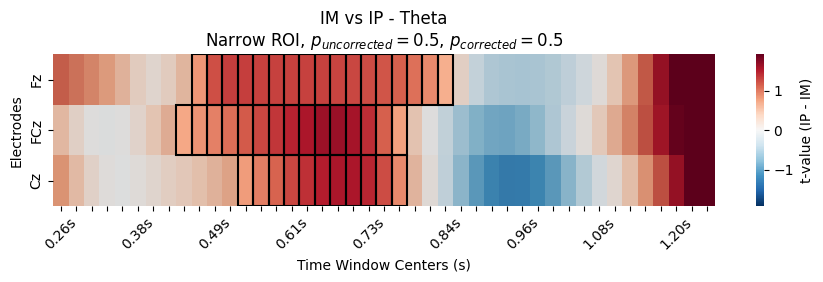

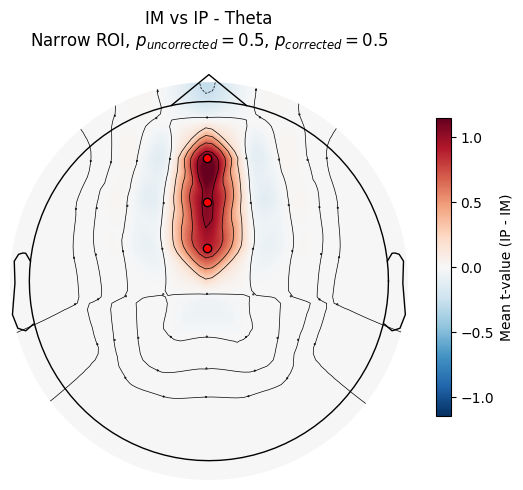


---> Plotting Unique Cluster #12 (ROI: narrow, p_uncorr=0.25, survived p_corr=0.5)


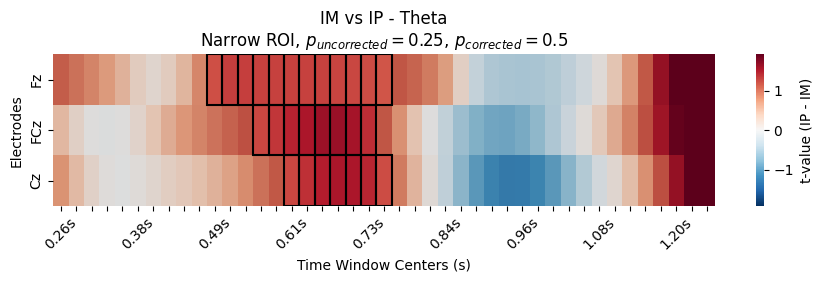

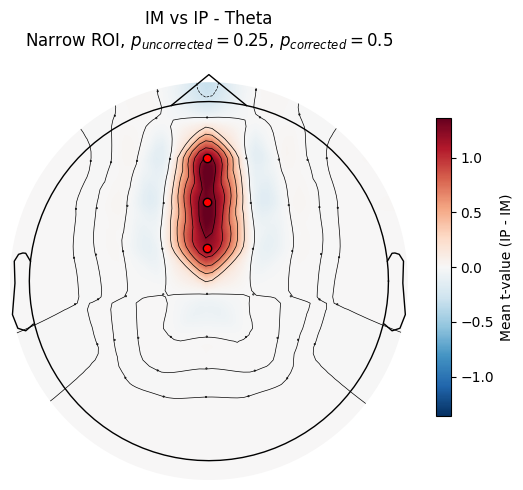


---> Plotting Unique Cluster #13 (ROI: narrow, p_uncorr=0.1, survived p_corr=0.4)


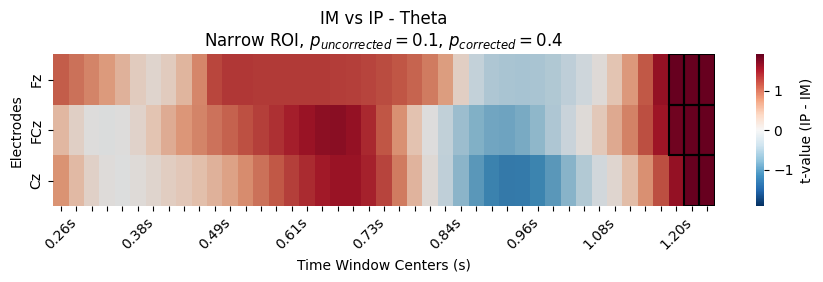

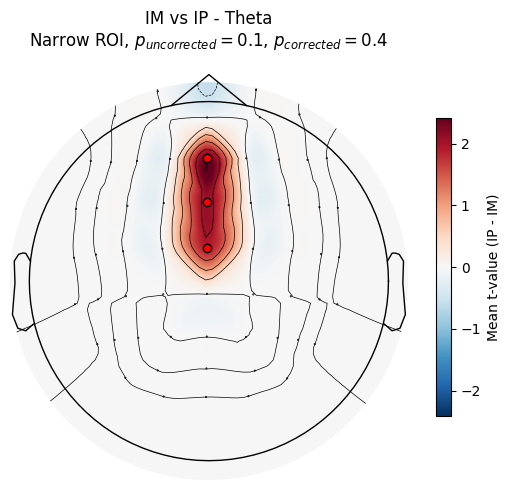


---> Plotting Unique Cluster #14 (ROI: narrow, p_uncorr=0.05, survived p_corr=0.25)


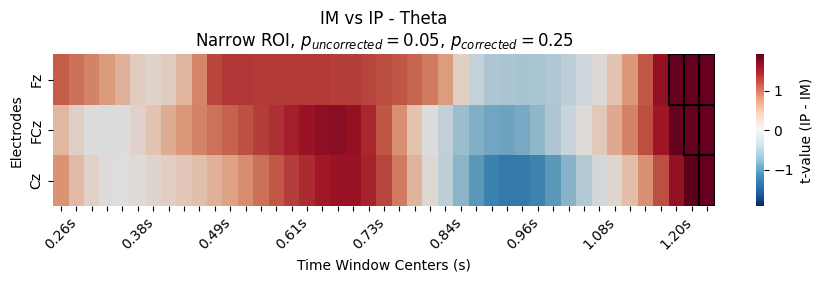

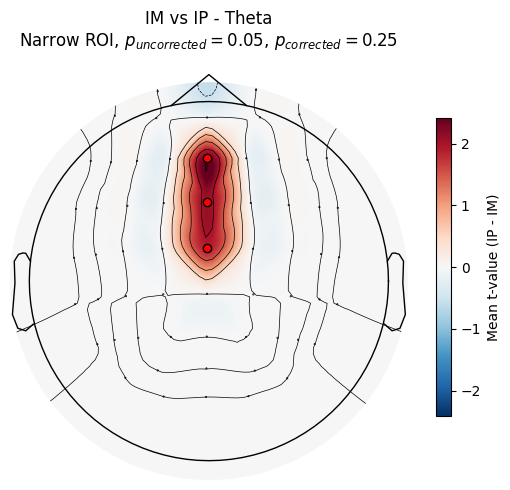


Plotting IM vs IP Alpha significant clusters:

---> Plotting Unique Cluster #1 (ROI: none, p_uncorr=0.25, survived p_corr=0.5)


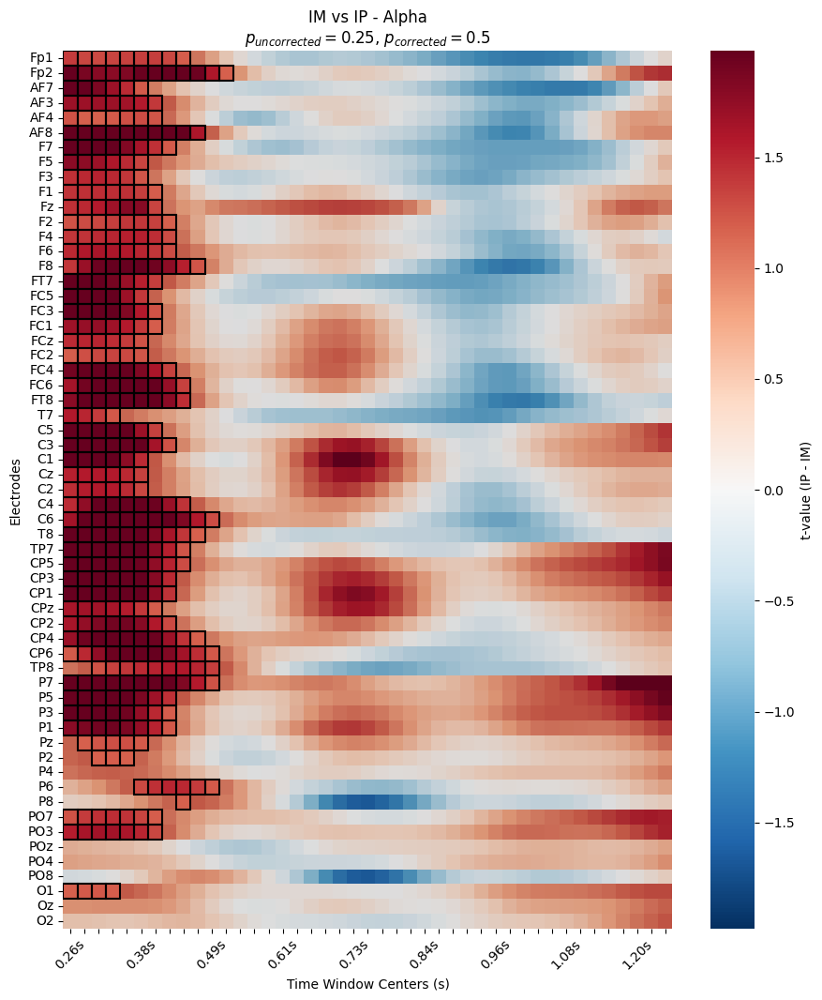

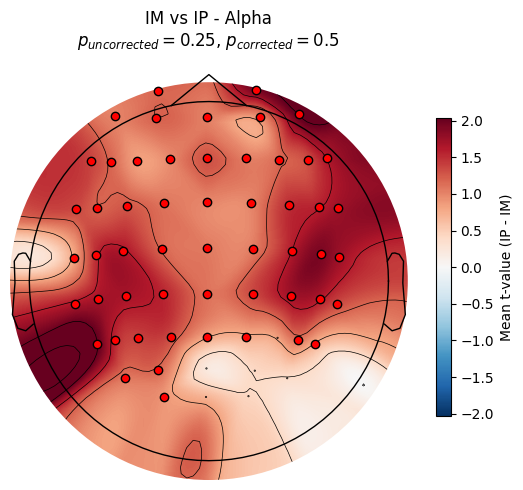


---> Plotting Unique Cluster #2 (ROI: none, p_uncorr=0.2, survived p_corr=0.5)


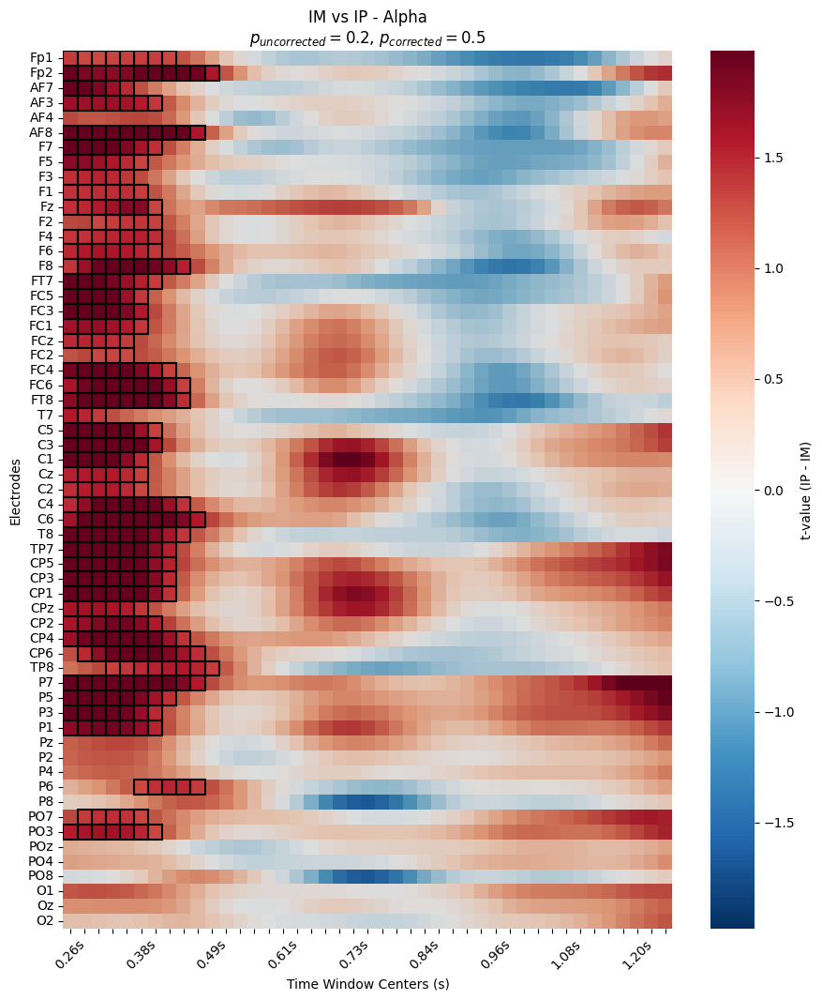

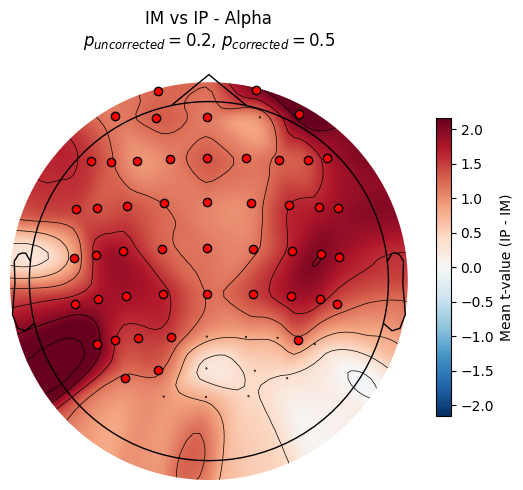


---> Plotting Unique Cluster #3 (ROI: none, p_uncorr=0.1, survived p_corr=0.5)


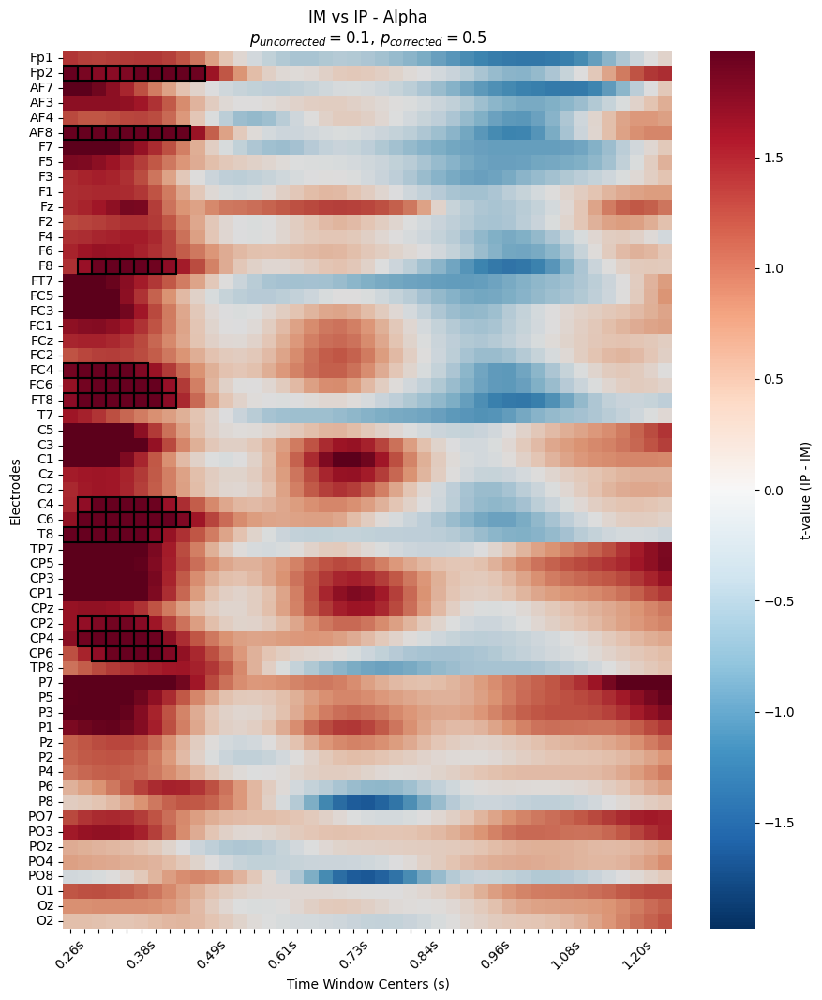

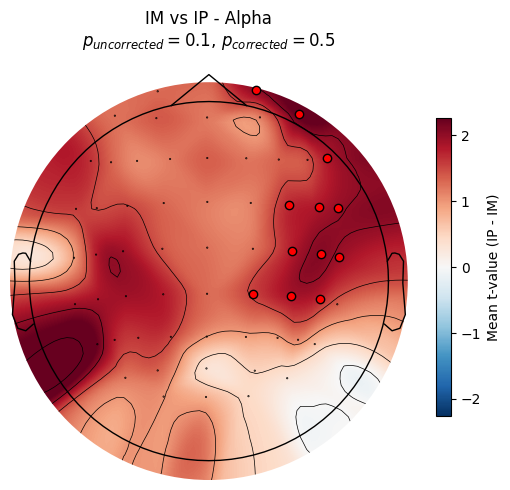


---> Plotting Unique Cluster #4 (ROI: none, p_uncorr=0.1, survived p_corr=0.5)


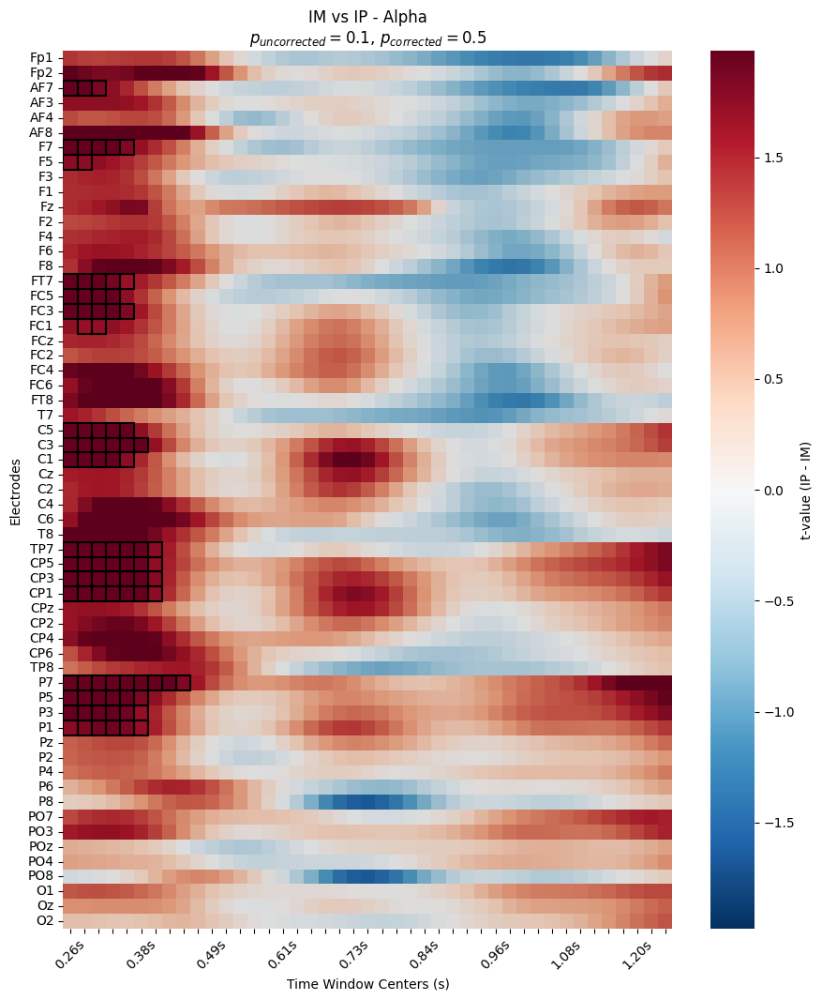

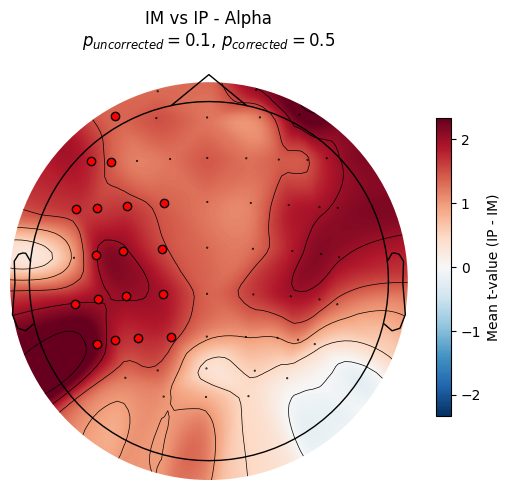


---> Plotting Unique Cluster #5 (ROI: none, p_uncorr=0.05, survived p_corr=0.4)


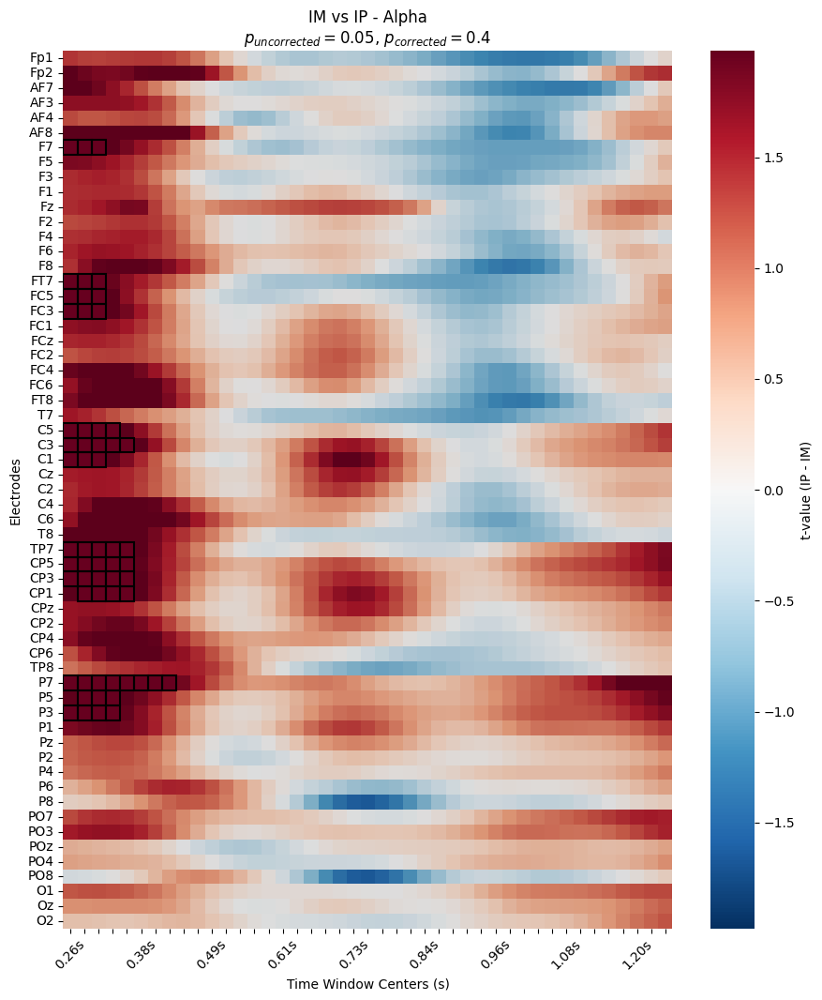

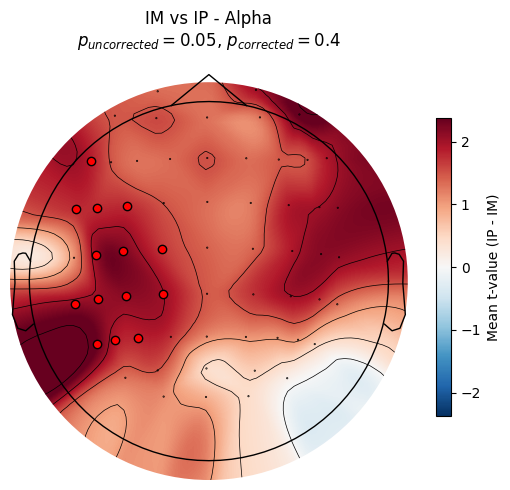


---> Plotting Unique Cluster #6 (ROI: none, p_uncorr=0.05, survived p_corr=0.5)


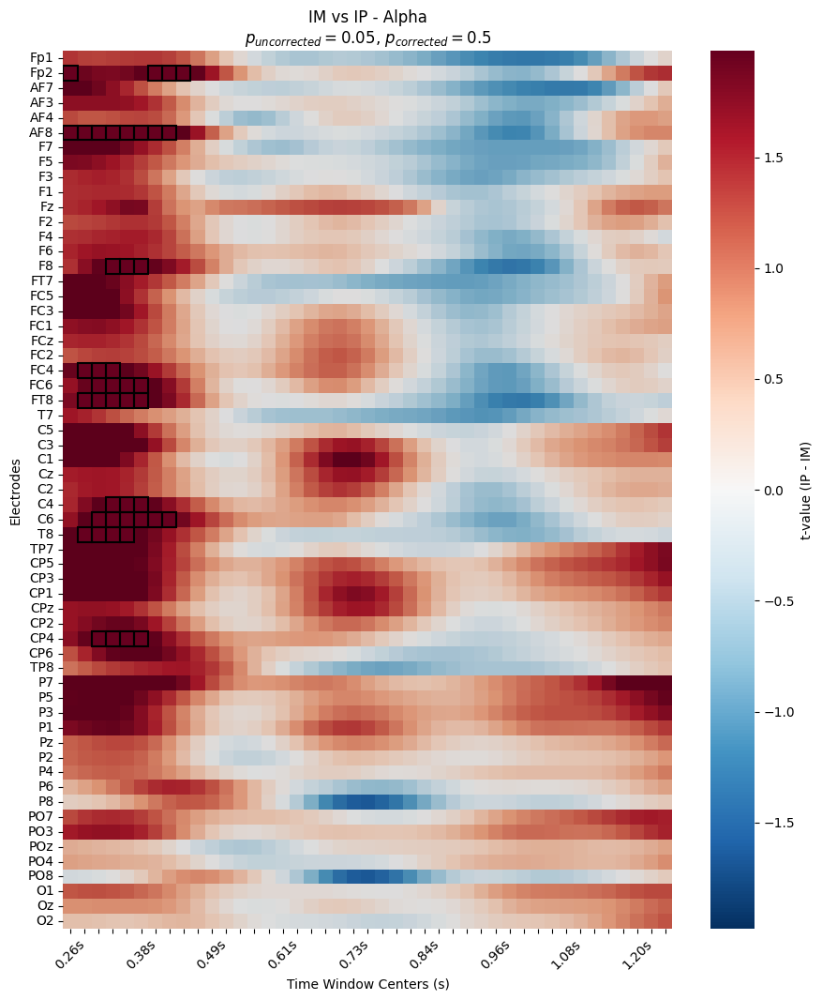

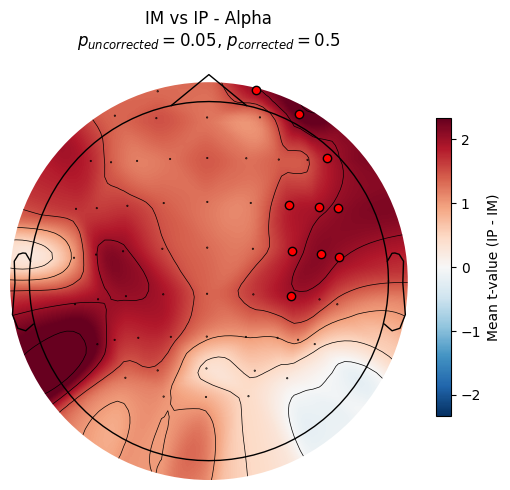


---> Plotting Unique Cluster #7 (ROI: none, p_uncorr=0.01, survived p_corr=0.5)


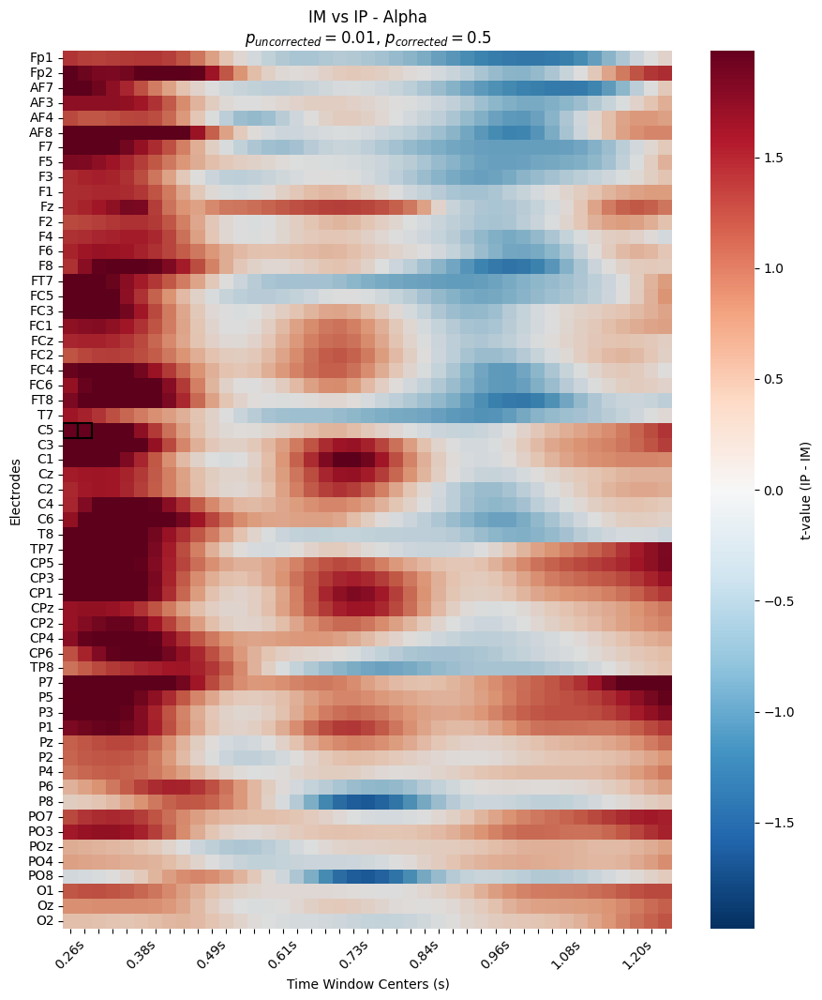

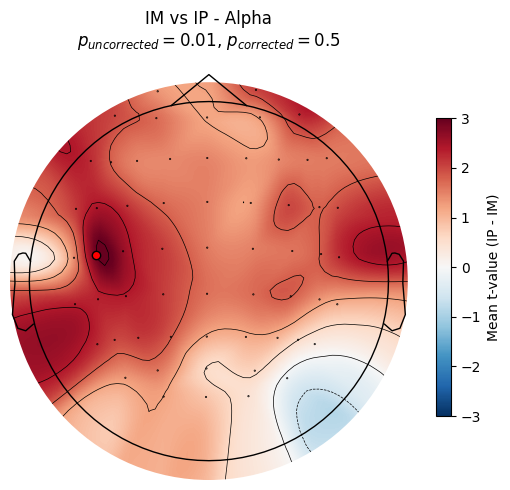


---> Plotting Unique Cluster #8 (ROI: none, p_uncorr=0.005, survived p_corr=0.35)


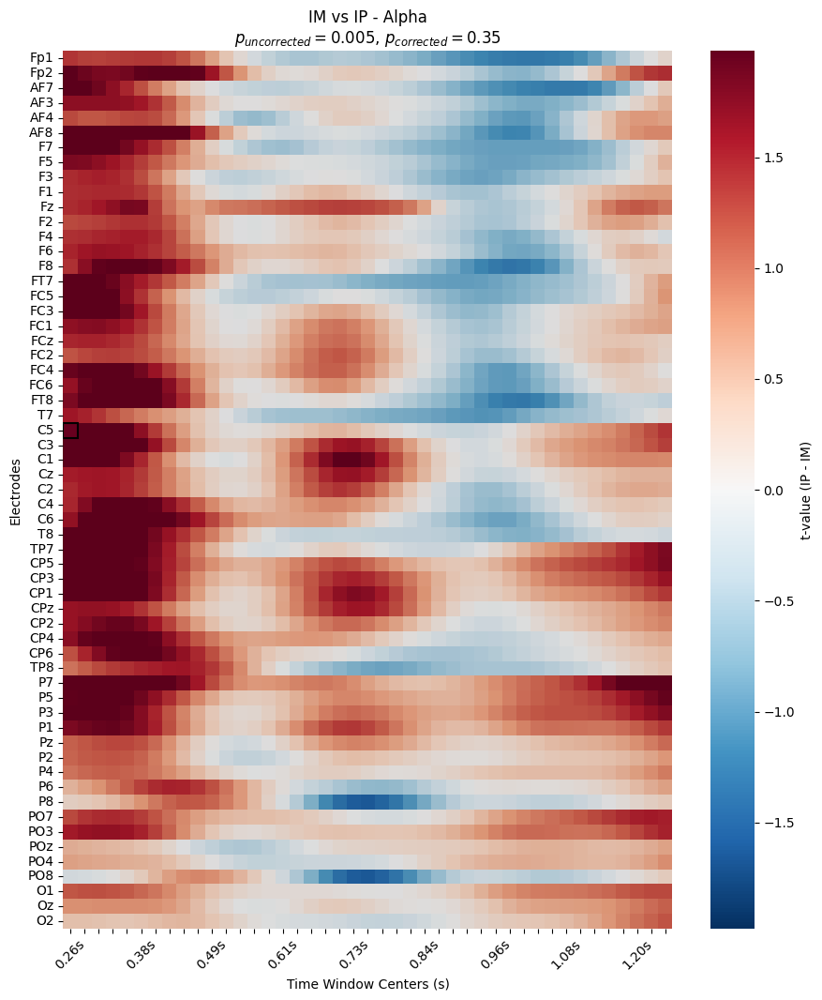

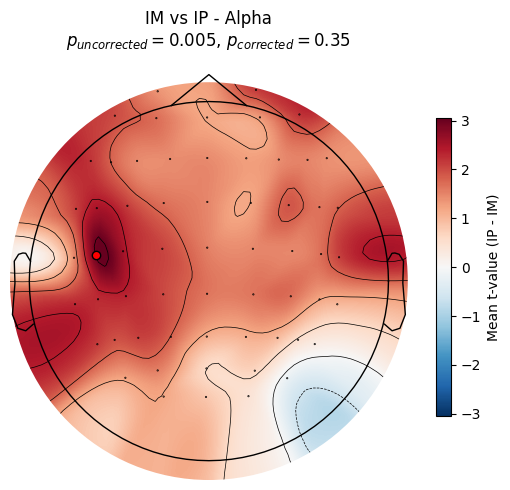


---> Plotting Unique Cluster #9 (ROI: broad, p_uncorr=0.25, survived p_corr=0.5)


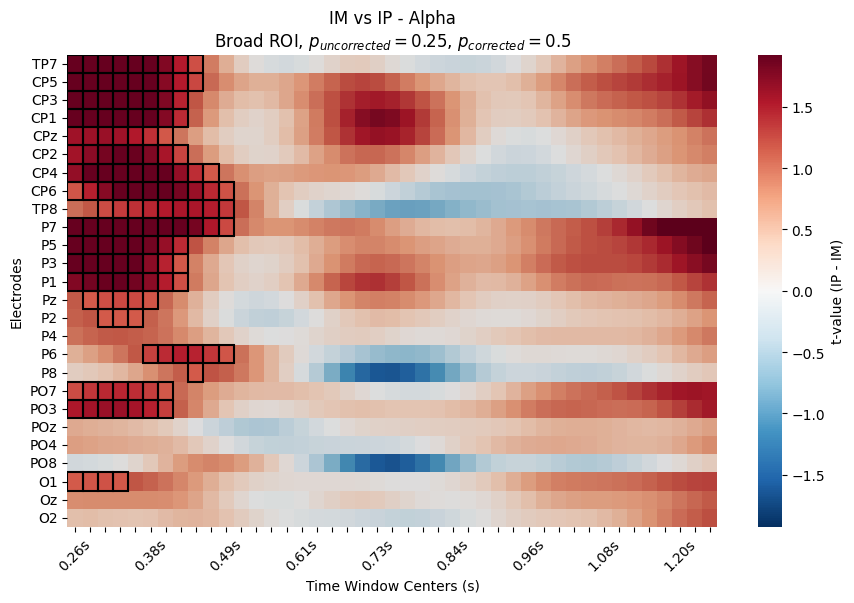

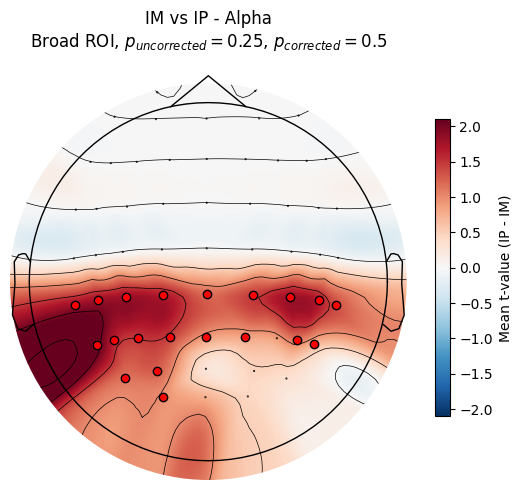


---> Plotting Unique Cluster #10 (ROI: broad, p_uncorr=0.2, survived p_corr=0.5)


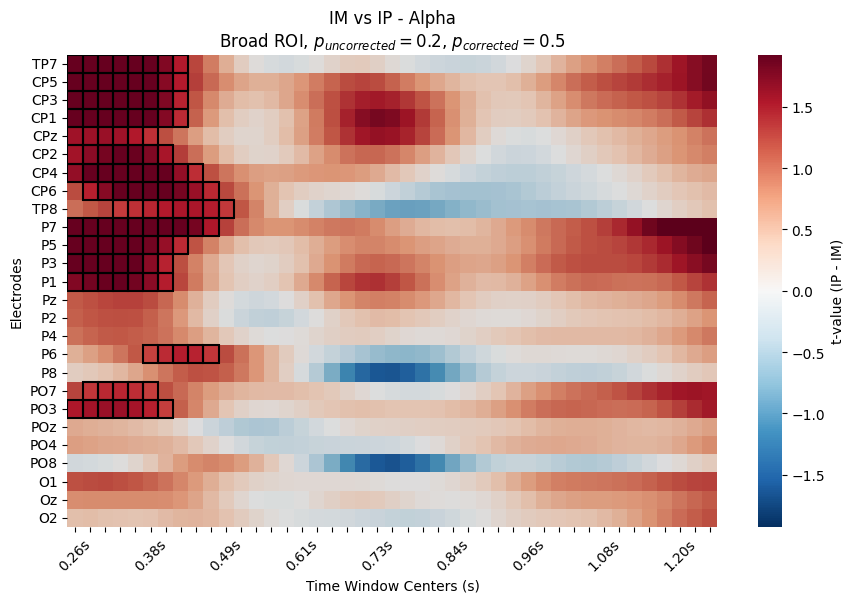

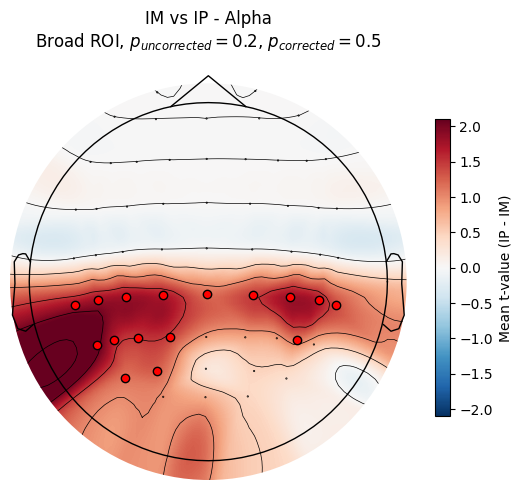


---> Plotting Unique Cluster #11 (ROI: broad, p_uncorr=0.1, survived p_corr=0.4)


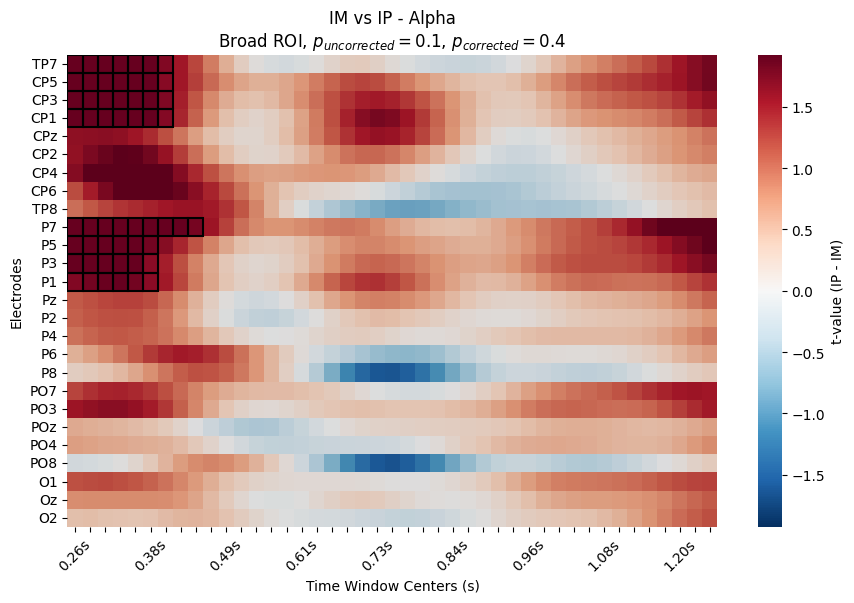

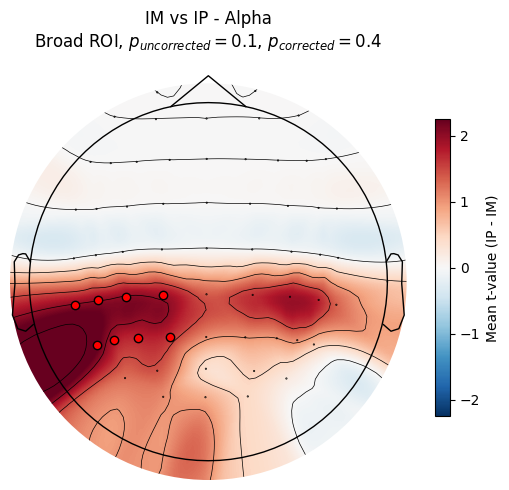


---> Plotting Unique Cluster #12 (ROI: broad, p_uncorr=0.05, survived p_corr=0.3)


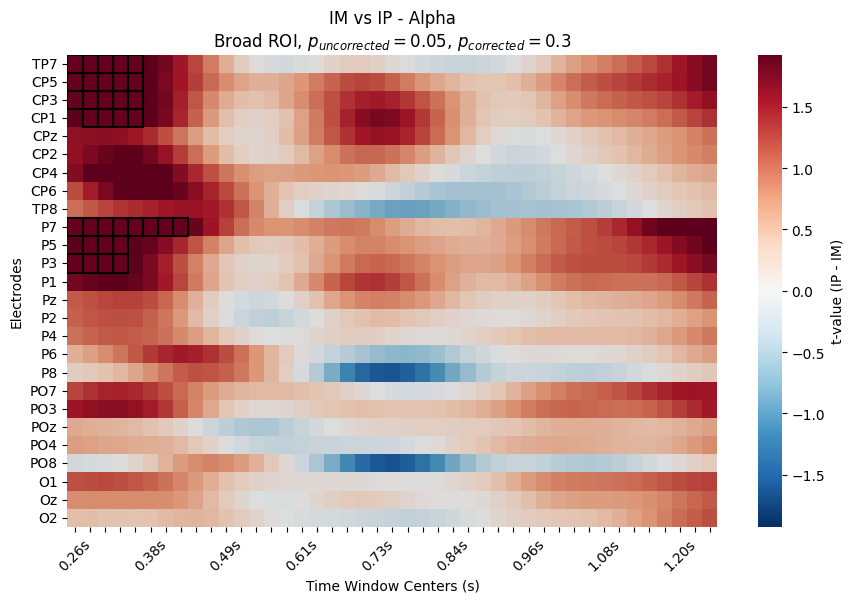

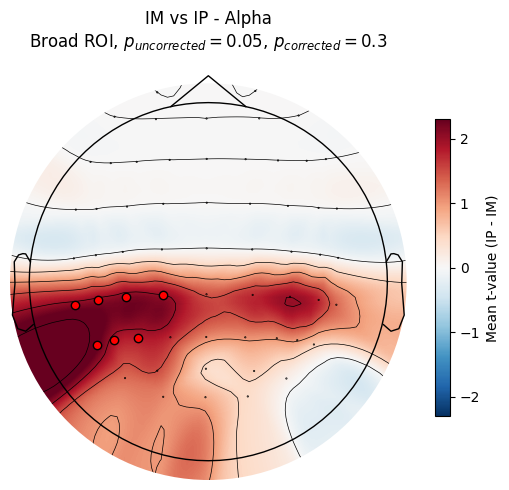


---> Plotting Unique Cluster #13 (ROI: narrow, p_uncorr=0.1, survived p_corr=0.5)


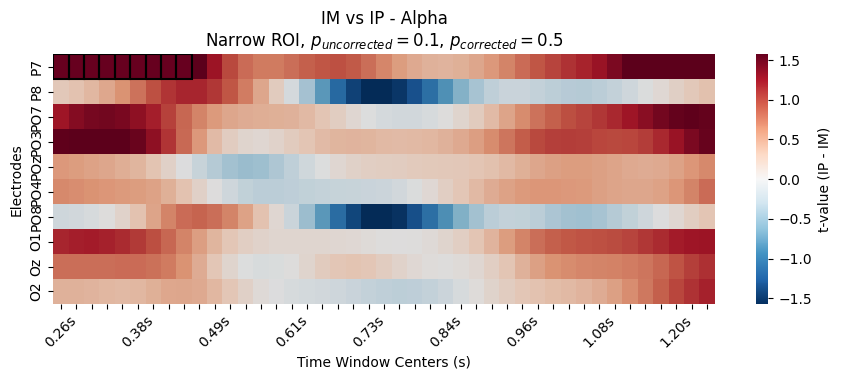

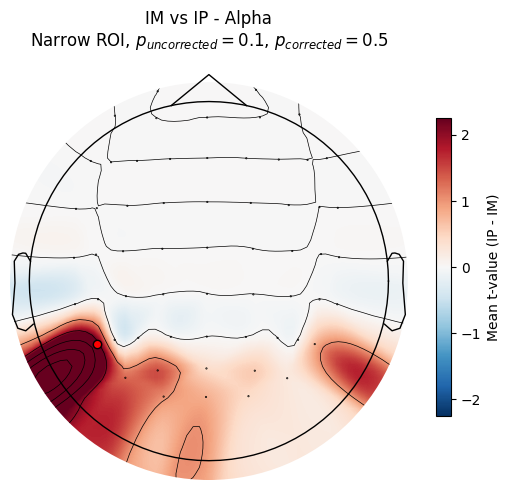


---> Plotting Unique Cluster #14 (ROI: narrow, p_uncorr=0.05, survived p_corr=0.35)


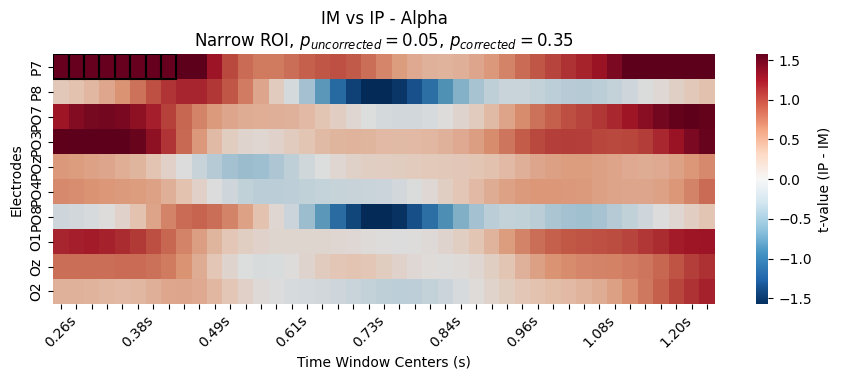

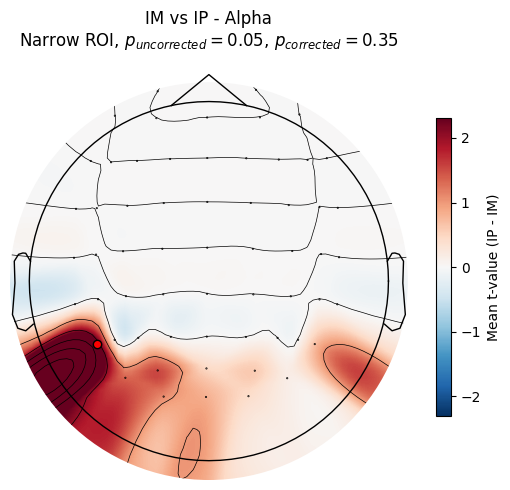


---> Plotting Unique Cluster #15 (ROI: narrow, p_uncorr=0.05, survived p_corr=0.5)


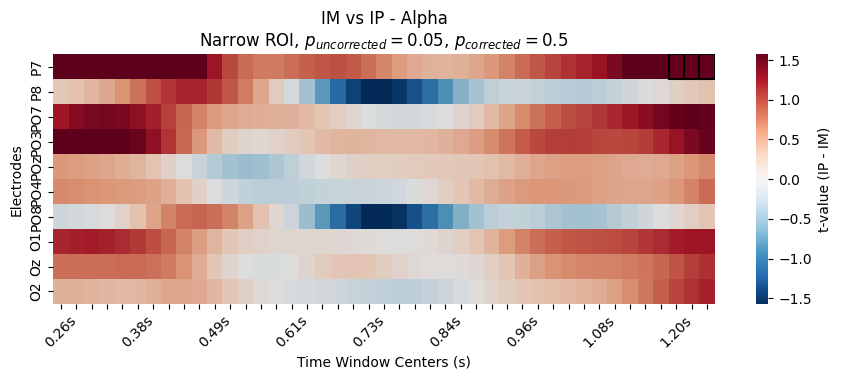

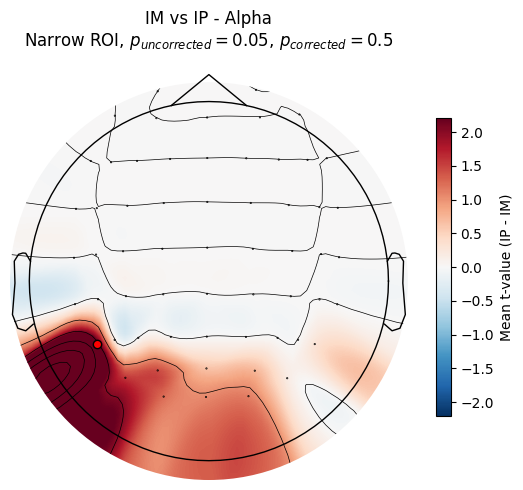

In [20]:
print("\nPlotting IM vs IP Theta significant clusters:")
plot_all_significant_unique_clusters(im_theta_res, im_theta_cache, "im_vs_ip", "theta", paths)

print("\nPlotting IM vs IP Alpha significant clusters:")
plot_all_significant_unique_clusters(im_alpha_res, im_alpha_cache, "im_vs_ip", "alpha", paths)

## 3. Export Chosen Clusters to JSON

Review the plotted clusters, make your selection, and specify them below to export to `cluster_definitions.json` for EEGNet.

Exported C_VS_IP - THETA (from ROI=narrow, p_uncorr=0.01, idx=0)
Exported C_VS_IP - ALPHA (from ROI=none, p_uncorr=0.001, idx=0)
Exported IM_VS_IP - THETA (from ROI=narrow, p_uncorr=0.05, idx=0)
Exported IM_VS_IP - ALPHA (from ROI=broad, p_uncorr=0.05, idx=0)

Saved chosen cluster definitions to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\cluster_definitions.json
{
    "c_vs_ip": {
        "theta": {
            "channels": [
                "Fz",
                "FCz"
            ],
            "tmin": 1.171875,
            "tmax": 1.2421875
        },
        "alpha": {
            "channels": [
                "FC3",
                "FC1",
                "FC2",
                "C3",
                "C1",
                "Cz",
                "C2",
                "CP3",
                "CP1",
                "CPz",
                "CP2",
                "CP4",
                "P5",
                "P3",
                "P1",
   

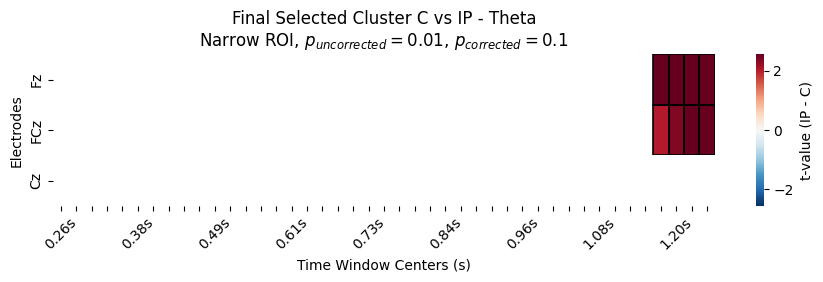

Final masked heatmap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\figures\final_masked_heatmap_c_vs_ip_theta_narrow.png


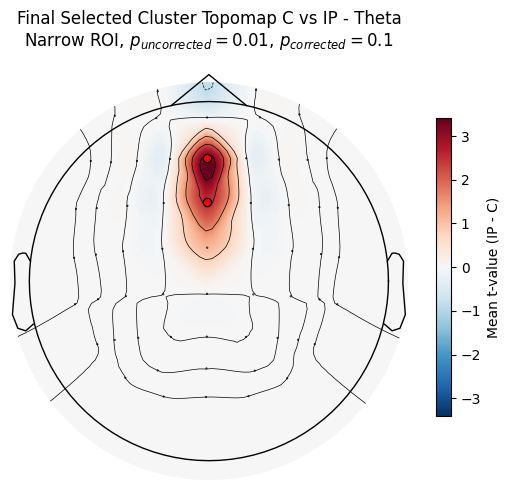

Final masked topomap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\figures\final_masked_topomap_c_vs_ip_theta_narrow.png


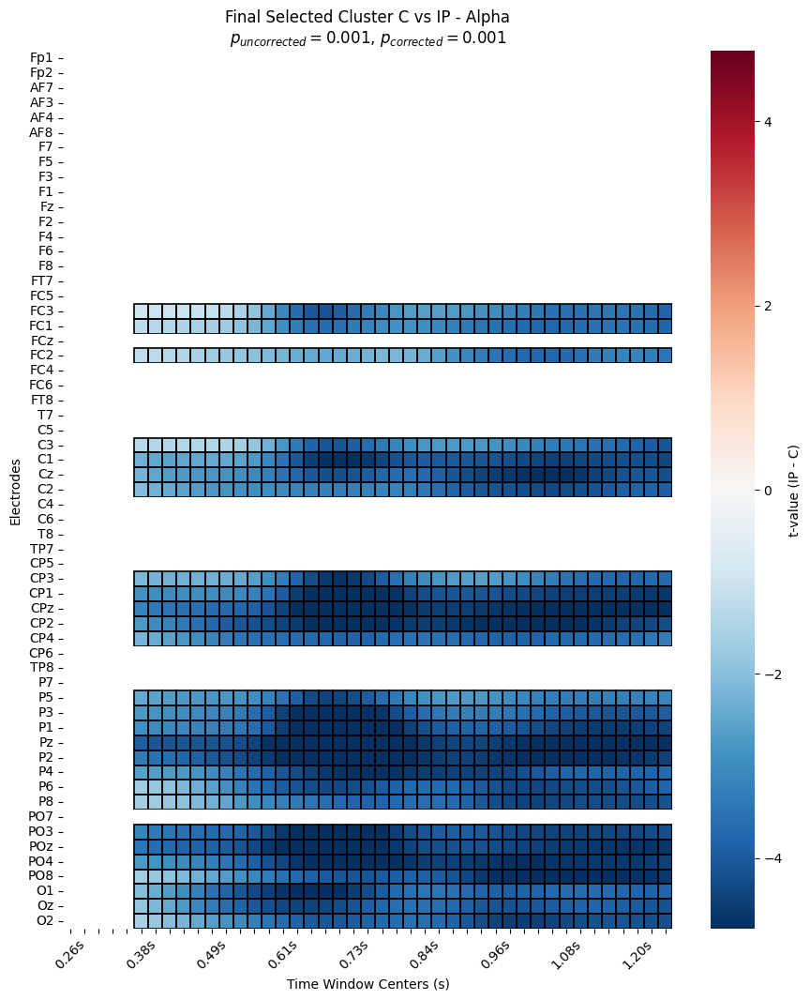

Final masked heatmap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\figures\final_masked_heatmap_c_vs_ip_alpha_none.png


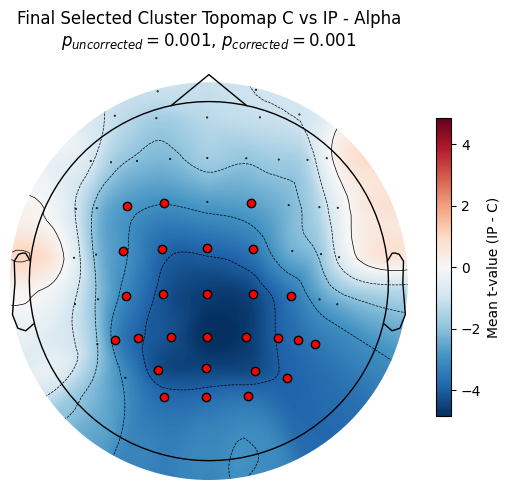

Final masked topomap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\figures\final_masked_topomap_c_vs_ip_alpha_none.png


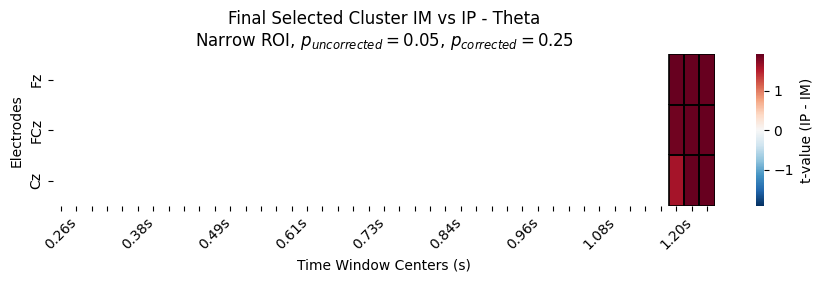

Final masked heatmap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\figures\final_masked_heatmap_im_vs_ip_theta_narrow.png


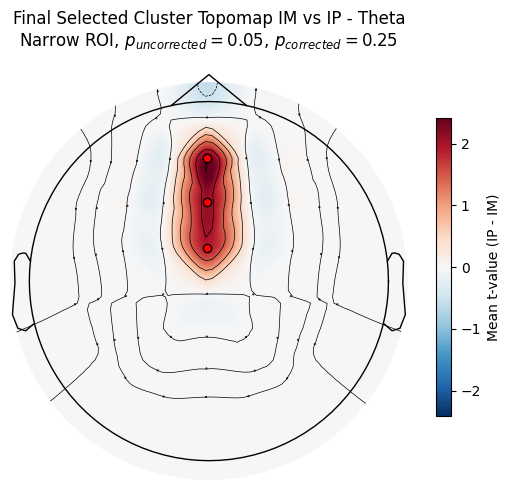

Final masked topomap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\figures\final_masked_topomap_im_vs_ip_theta_narrow.png


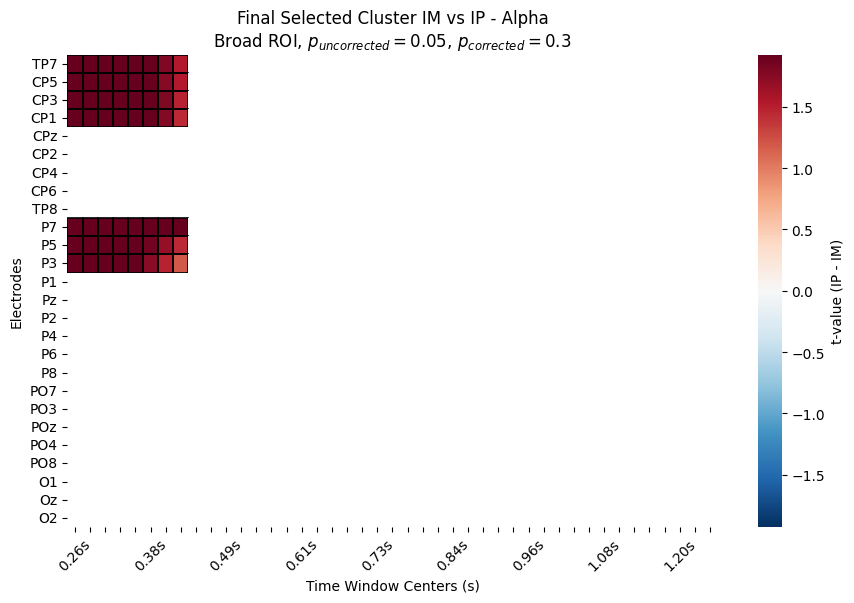

Final masked heatmap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\figures\final_masked_heatmap_im_vs_ip_alpha_broad.png


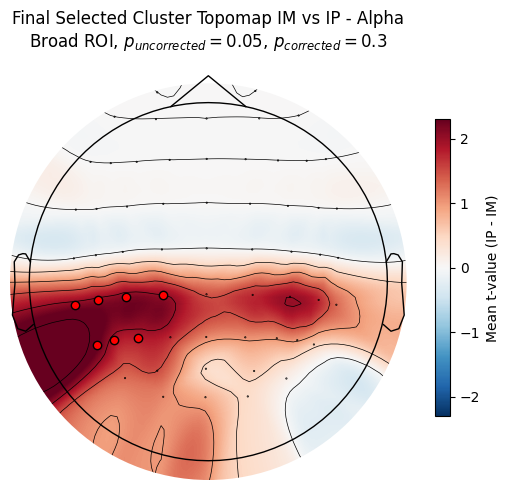

Final masked topomap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\figures\final_masked_topomap_im_vs_ip_alpha_broad.png


In [ ]:
# MANUALLY SPECIFY CHOSEN THRESHOLDS FOR EXPORT TO EEGNET HERE!
CHOSEN_CLUSTERS = {
    "c_vs_ip": {
        "alpha": {
            "roi_mode": "none",
            "p_uncorrected": 0.001,
            "cluster_idx": 0,
            "fallback_res": c_alpha_res,
            "cache": c_alpha_cache,
        },
        "theta": {
            "roi_mode": "narrow",
            "p_uncorrected": 0.01,
            "cluster_idx": 0,
            "fallback_res": c_theta_res,
            "cache": c_theta_cache,
        },
    },
    "im_vs_ip": {
        "alpha": {
            "roi_mode": "broad",
            "p_uncorrected": 0.05,
            "cluster_idx": 0,
            "fallback_res": im_alpha_res,
            "cache": im_alpha_cache,
        },
        "theta": {
            "roi_mode": "narrow",
            "p_uncorrected": 0.05,
            "cluster_idx": 0,
            "fallback_res": im_theta_res,
            "cache": im_theta_cache,
        },
    },
}


def select_and_export_chosen_clusters():
    export_definitions = {
        "c_vs_ip": {
            "theta": {"channels": [], "tmin": None, "tmax": None},
            "alpha": {"channels": [], "tmin": None, "tmax": None},
        },
        "im_vs_ip": {
            "theta": {"channels": [], "tmin": None, "tmax": None},
            "alpha": {"channels": [], "tmin": None, "tmax": None},
        },
    }

    for task in ["c_vs_ip", "im_vs_ip"]:
        for band in ["theta", "alpha"]:
            config = CHOSEN_CLUSTERS[task][band]
            roi_mode = config["roi_mode"]
            p_uncorr = config["p_uncorrected"]
            c_idx = config["cluster_idx"]
            res_list = config["fallback_res"]

            if p_uncorr is not None and c_idx is not None:
                # Find matching cluster in results list
                match = [
                    c
                    for c in res_list
                    if c["roi_mode"] == roi_mode and c["p_uncorrected"] == p_uncorr and c["cluster_idx"] == c_idx
                ]
                if match:
                    export_definitions[task][band] = {
                        "channels": match[0]["channels"],
                        "tmin": match[0]["tmin"],
                        "tmax": match[0]["tmax"],
                    }
                    print(
                        f"Exported {task.upper()} - {band.upper()} (from ROI={roi_mode}, p_uncorr={p_uncorr}, idx={c_idx})"
                    )
                    continue

            # Fallback check: if anything survived at p_corrected <= 0.05, export first one automatically
            strict_sig = [c for c in res_list if c["p_corrected"] <= 0.05]
            if strict_sig:
                export_definitions[task][band] = {
                    "channels": strict_sig[0]["channels"],
                    "tmin": strict_sig[0]["tmin"],
                    "tmax": strict_sig[0]["tmax"],
                }
                print(
                    f"Exported strict significant {task.upper()} - {band.upper()} (ROI={strict_sig[0]['roi_mode']}, p_uncorr={strict_sig[0]['p_uncorrected']})"
                )
            else:
                print(f"No cluster exported for {task.upper()} - {band.upper()} (will use EEGNet defaults)")

    out_json_dir = paths.analysis_root / "clustering"
    out_json_dir.mkdir(parents=True, exist_ok=True)
    out_json_path = out_json_dir / "cluster_definitions.json"
    with open(out_json_path, "w") as f:
        json.dump(export_definitions, f, indent=4)
    print(f"\nSaved chosen cluster definitions to: {out_json_path}")
    print(json.dumps(export_definitions, indent=4))


select_and_export_chosen_clusters()


def plot_final_masked_cluster(task_name, band_name, config, paths):
    """
    Plot the chosen cluster with solid white masking for non-cluster regions
    and t-values shown for the entire duration of the cluster's channels.
    """
    roi_mode = config["roi_mode"]
    p_uncorr = config["p_uncorrected"]
    c_idx = config["cluster_idx"]
    res_list = config["fallback_res"]
    diff_maps_cache = config["cache"]

    cluster = None
    if p_uncorr is not None and c_idx is not None:
        match = [
            c
            for c in res_list
            if c["roi_mode"] == roi_mode and c["p_uncorrected"] == p_uncorr and c["cluster_idx"] == c_idx
        ]
        if match:
            cluster = match[0]

    if cluster is None:
        strict_sig = [c for c in res_list if c["p_corrected"] <= 0.05]
        if strict_sig:
            cluster = strict_sig[0]
            roi_mode = cluster["roi_mode"]

    if cluster is None:
        print(f"No significant cluster to plot for {task_name.upper()} - {band_name.upper()}.")
        return

    # Unpack 5 elements
    X_diff, times, ch_names_to_use, info_to_use, full_info = diff_maps_cache[roi_mode]

    t_vals, _ = ttest_1samp(X_diff, popmean=0.0, axis=0)
    t_vals = t_vals.T

    ch_to_idx = {ch: i for i, ch in enumerate(ch_names_to_use)}
    present_order = [ch for ch in CHANNEL_ORDER if ch in ch_to_idx]
    ordered_idx = [ch_to_idx[ch] for ch in present_order]
    t_vals_ordered = t_vals[ordered_idx, :]

    # Linear function: y = m*x + n where x is len(present_order), m=0.14, n=2.5
    fig_height = len(present_order) * 0.14 + 2.5
    fig, ax = plt.subplots(figsize=(9, fig_height))
    vmax = float(np.percentile(np.abs(t_vals_ordered), 95))
    if vmax == 0:
        vmax = 1.0

    xticklabels = [f"{t:.2f}s" if idx % 5 == 0 else "" for idx, t in enumerate(times)]

    sns.heatmap(
        t_vals_ordered,
        ax=ax,
        cmap="RdBu_r",
        center=0.0,
        vmin=-vmax,
        vmax=vmax,
        xticklabels=xticklabels,
        yticklabels=present_order,
        cbar_kws={"label": f"t-value ({'IP - C' if task_name == 'c_vs_ip' else 'IP - IM'})"},
    )

    ch_in_cluster = set(cluster["channels"])
    tmin_val, tmax_val = cluster["tmin"], cluster["tmax"]

    cluster_box_mask = np.zeros((len(present_order), len(times)), dtype=bool)
    for i, ch in enumerate(present_order):
        if ch in ch_in_cluster:
            for j, t in enumerate(times):
                if tmin_val <= t <= tmax_val:
                    cluster_box_mask[i, j] = True

    for i in range(t_vals_ordered.shape[0]):
        for j in range(t_vals_ordered.shape[1]):
            if cluster_box_mask[i, j]:
                ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", linewidth=1.2))
            else:
                ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=True, color="white", linewidth=0))

    # LaTeX formatting for p_uncorrected and p_corrected and omit NONE ROI
    roi_label = f"{roi_mode.capitalize()} ROI, " if roi_mode.lower() in ["broad", "narrow"] else ""
    ax.set_title(
        f"Final Selected Cluster {task_name.split('_')[0].upper()} vs {task_name.split('_')[-1].upper()} - {band_name.capitalize()}\n{roi_label}$p_{{uncorrected}} = {cluster['p_uncorrected']}$, $p_{{corrected}} = {cluster['p_corrected']}$"
    )
    ax.set_xlabel("Time Window Centers (s)")
    ax.set_ylabel("Electrodes")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()

    heatmap_path = paths.figures_dir / f"final_masked_heatmap_{task_name}_{band_name}_{roi_mode}.png"
    plt.savefig(heatmap_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Final masked heatmap saved to: {heatmap_path}")

    # Topomap
    topo_path = paths.figures_dir / f"final_masked_topomap_{task_name}_{band_name}_{roi_mode}.png"
    fig, ax = plt.subplots(figsize=(6, 5))
    active_times = list(set(cluster["mask"][0]))
    t_avg = np.mean(t_vals[:, active_times], axis=1)
    t_avg_full = np.zeros(len(full_info.ch_names))
    mask_full = np.zeros(len(full_info.ch_names), dtype=bool)
    for ch_idx, ch_name in enumerate(ch_names_to_use):
        full_idx = full_info.ch_names.index(ch_name)
        t_avg_full[full_idx] = t_avg[ch_idx]
        if ch_name in cluster["channels"]:
            mask_full[full_idx] = True
    t_max = max(abs(t_avg_full.min()), abs(t_avg_full.max()))
    if t_max == 0:
        t_max = 1.0
    im, _ = mne.viz.plot_topomap(
        t_avg_full,
        full_info,
        axes=ax,
        mask=mask_full,
        mask_params=dict(marker="o", markerfacecolor="red", markersize=6, markeredgecolor="k"),
        cmap="RdBu_r",
        vlim=(-t_max, t_max),
        show=False,
    )
    cbar = fig.colorbar(im, ax=ax, orientation="vertical", shrink=0.7)
    cbar.set_label(f"Mean t-value ({'IP - C' if task_name == 'c_vs_ip' else 'IP - IM'})")
    ax.set_title(
        f"Final Selected Cluster Topomap {task_name.split('_')[0].upper()} vs {task_name.split('_')[-1].upper()} - {band_name.capitalize()}\n{roi_label}$p_{{uncorrected}} = {cluster['p_uncorrected']}$, $p_{{corrected}} = {cluster['p_corrected']}$"
    )
    plt.tight_layout()
    plt.savefig(topo_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Final masked topomap saved to: {topo_path}")


print("\nGenerating final masked plots for the selected 4 clusters...")
for task in ["c_vs_ip", "im_vs_ip"]:
    for band in ["theta", "alpha"]:
        plot_final_masked_cluster(task, band, CHOSEN_CLUSTERS[task][band], paths)